In [10]:
alle_laender = df['country'].unique()

# Optional sortieren
alle_laender = sorted(alle_laender)

# Anzeigen
for land in alle_laender:
    print(land)

KeyError: 'country'

In [ ]:
import pandas as pd

df = pd.read_csv("data/owid-co2-data.csv")
df.head()


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
laender = ['Germany', 'United States', 'China']
df_laender = df[df['country'].isin(laender)]


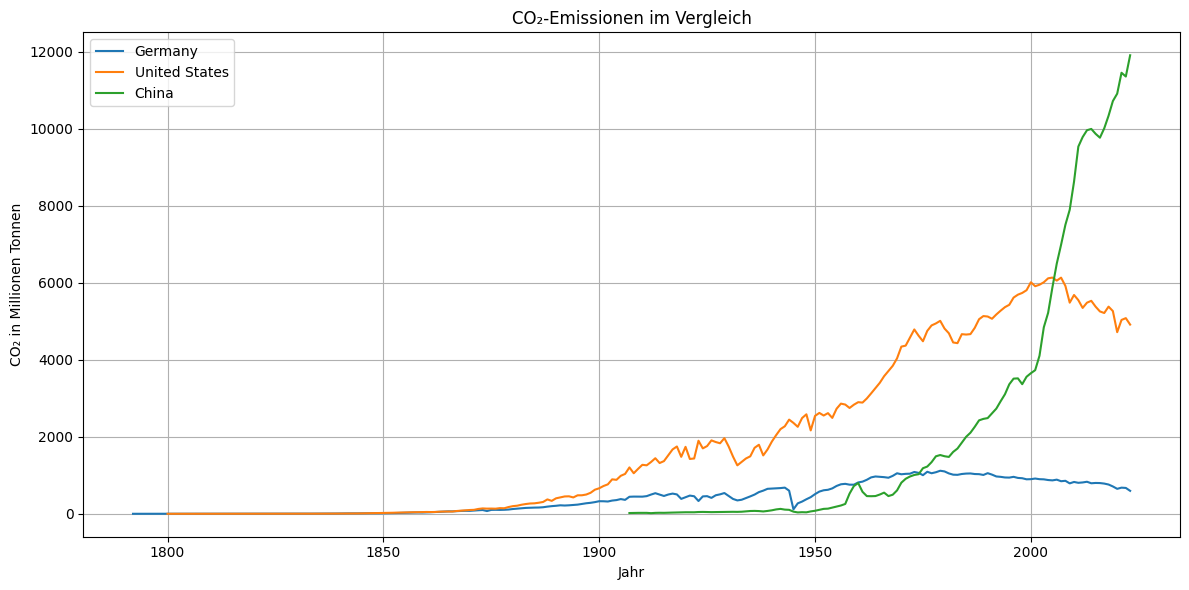

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2'], label=land)

plt.title('CO₂-Emissionen im Vergleich')
plt.xlabel('Jahr')
plt.ylabel('CO₂ in Millionen Tonnen')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


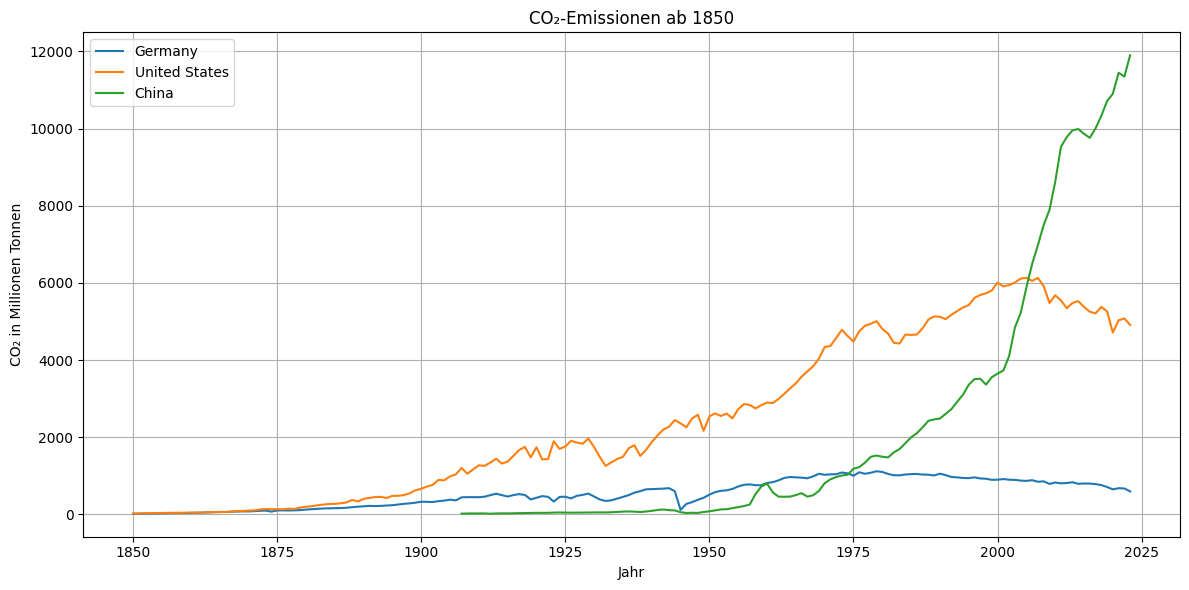

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Länder definieren
laender = ['Germany', 'United States', 'China']
df_laender = df[df['country'].isin(laender)]

# Jahr einschränken (z. B. ab 1990)
startjahr = 1850
df_laender = df_laender[df_laender['year'] >= startjahr]

# Plot
plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2'], label=land)

plt.title(f'CO₂-Emissionen ab {startjahr}')
plt.xlabel('Jahr')
plt.ylabel('CO₂ in Millionen Tonnen')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


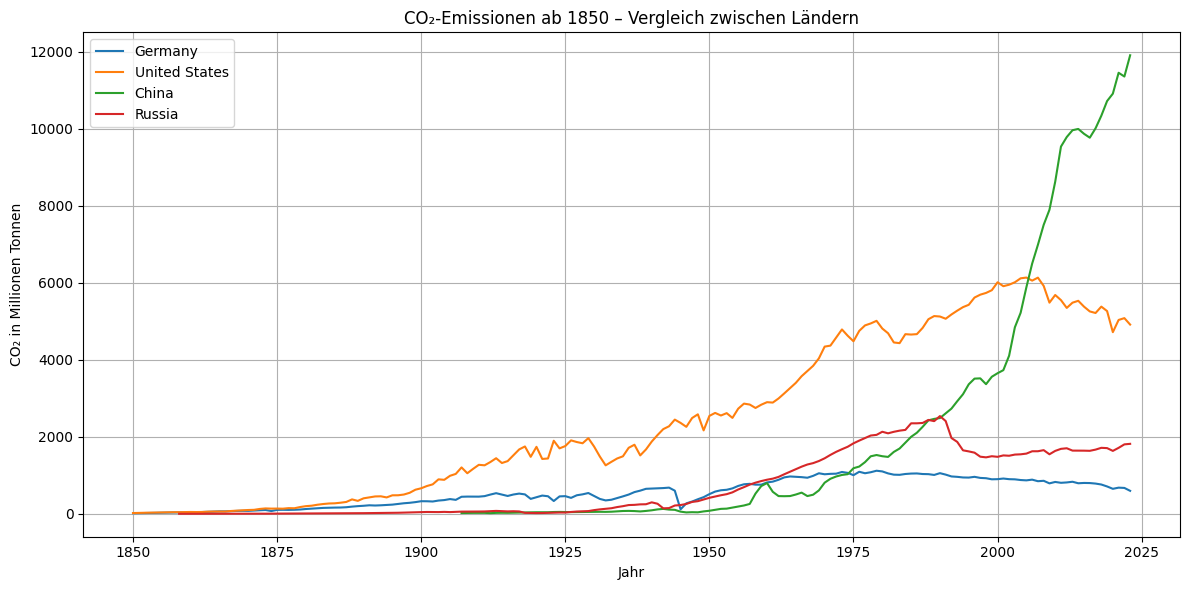

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Länder definieren (inkl. Indien)
laender = ['Germany', 'United States', 'China', 'Russia']
df_laender = df[df['country'].isin(laender)]

# Jahr einschränken (ab 1990)
startjahr = 1850
df_laender = df_laender[df_laender['year'] >= startjahr]

# Plot
plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2'], label=land)

plt.title(f'CO₂-Emissionen ab {startjahr} – Vergleich zwischen Ländern')
plt.xlabel('Jahr')
plt.ylabel('CO₂ in Millionen Tonnen')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


<function matplotlib.pyplot.grid(visible: 'bool | None' = None, which: "Literal['major', 'minor', 'both']" = 'major', axis: "Literal['both', 'x', 'y']" = 'both', **kwargs) -> 'None'>

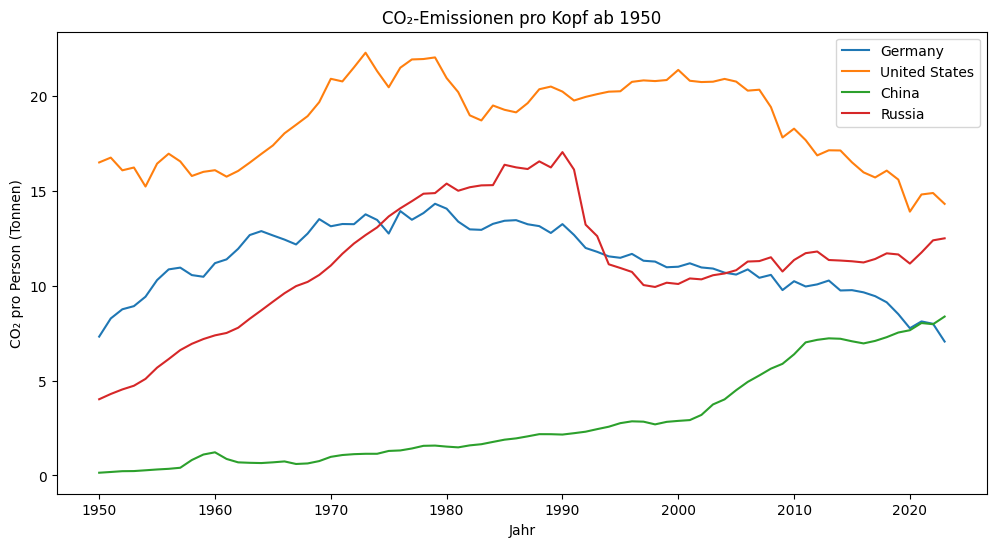

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Länder auswählen
laender = ['Germany', 'United States', 'China', 'Russia']
df_laender = df[df['country'].isin(laender)]

# Jahr einschränken
startjahr = 1950
df_laender = df_laender[df_laender['year'] >= startjahr]

# Plot: CO₂ pro Kopf
plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2_per_capita'], label=land)

plt.title(f'CO₂-Emissionen pro Kopf ab {startjahr}')
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Person (Tonnen)')
plt.legend()
plt.grid


In [ ]:
import pandas as pd
import plotly.express as px

# CO₂-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Nur Daten für ein bestimmtes Jahr (z. B. 2020)
jahr = 2020
df_jahr = df[df['year'] == jahr]

# Länder ohne gültigen ISO-Code oder ohne CO2 ausschließen
df_jahr = df_jahr[df_jahr['iso_code'].notna() & df_jahr['co2'].notna()]

# Choropleth-Karte erstellen
fig = px.choropleth(
    df_jahr,
    locations="iso_code",        # Ländercode (ISO 3166-1 alpha-3)
    color="co2",                 # Farbabstufung basierend auf CO₂-Werten
    hover_name="country",        # Name beim Hover
    color_continuous_scale="Reds",
    title=f"CO₂-Emissionen weltweit ({jahr})",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.show()



In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Jupyter-Renderer aktivieren
pio.renderers.default = "notebook_connected"  # Oder "notebook"

# CO₂-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Nur Jahr 2020 und gültige Länder
df_2020 = df[(df['year'] == 2020) & df['iso_code'].notna() & df['co2'].notna()]

# Choropleth-Karte
fig = px.choropleth(
    df_2020,
    locations="iso_code",
    color="co2",
    hover_name="country",
    color_continuous_scale="Reds",
    title="CO₂-Emissionen weltweit (2020)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer für Jupyter Notebook
pio.renderers.default = "notebook_connected"

# CO₂-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Nur Länder mit gültigem ISO-Code und CO₂-Daten ab 1990
df_anim = df[
    (df['year'] >= 1990) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

# Animierte Choropleth-Karte
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale="Reds",
    title="CO₂-Emissionen weltweit (1990 – aktuell)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'},
    range_color=(0, df_anim['co2'].quantile(0.98))  # Extremwerte glätten
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV-Datei einlesen (ggf. Pfad anpassen)
df = pd.read_csv("data/nasa_temperature.csv", skiprows=1)

# Erste Spalte umbenennen (sollte 'Year' heißen)
df.rename(columns={df.columns[0]: 'Year'}, inplace=True)

# Spalte 'J-D' enthält die Jahresdurchschnitts-Temperaturabweichung (relative zur Basisperiode 1951–1980)
df = df[['Year', 'J-D']]
df = df.dropna()  # NaN-Werte entfernen
df['J-D'] = pd.to_numeric(df['J-D'], errors='coerce')  # falls Werte als Text vorliegen

# Plot erstellen
plt.figure(figsize=(12, 6))
plt.plot(df['Year'], df['J-D'], color='darkred', linewidth=2)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.title('Globale Temperaturveränderung seit 1880 (NASA GISTEMP)')
plt.xlabel('Jahr')
plt.ylabel('Abweichung in °C (vom Mittel 1951–1980)')
plt.grid(True)
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/Users/adam/Documents/vs-code/2. Semester/Data Science II/nasa_tempeture.csv'

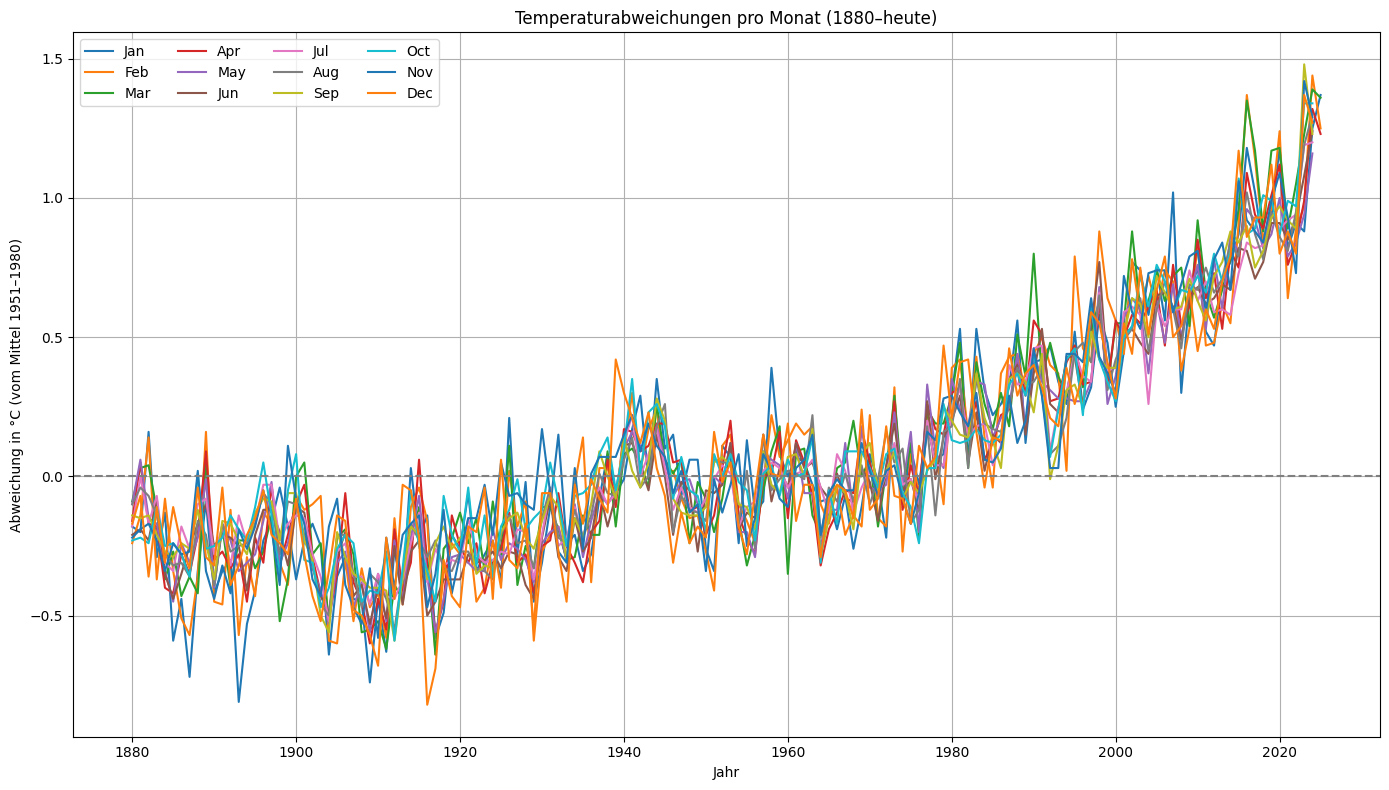

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# NASA-Daten laden (ggf. Pfad anpassen)
df = pd.read_csv("data/nasa_temperature.csv", skiprows=1)

# Spaltennamen bereinigen
df.rename(columns={df.columns[0]: 'Year'}, inplace=True)

# Monatsdaten extrahieren (nur Jan–Dec, keine Jahresmittelwerte)
monate = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df_monate = df[['Year'] + monate].dropna()

# Alle Werte zu float konvertieren
for monat in monate:
    df_monate[monat] = pd.to_numeric(df_monate[monat], errors='coerce')

# Plot
plt.figure(figsize=(14, 8))

for monat in monate:
    plt.plot(df_monate['Year'], df_monate[monat], label=monat)

plt.axhline(0, color='gray', linestyle='--')
plt.title("Temperaturabweichungen pro Monat (1880–heute)")
plt.xlabel("Jahr")
plt.ylabel("Abweichung in °C (vom Mittel 1951–1980)")
plt.legend(ncol=4, loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


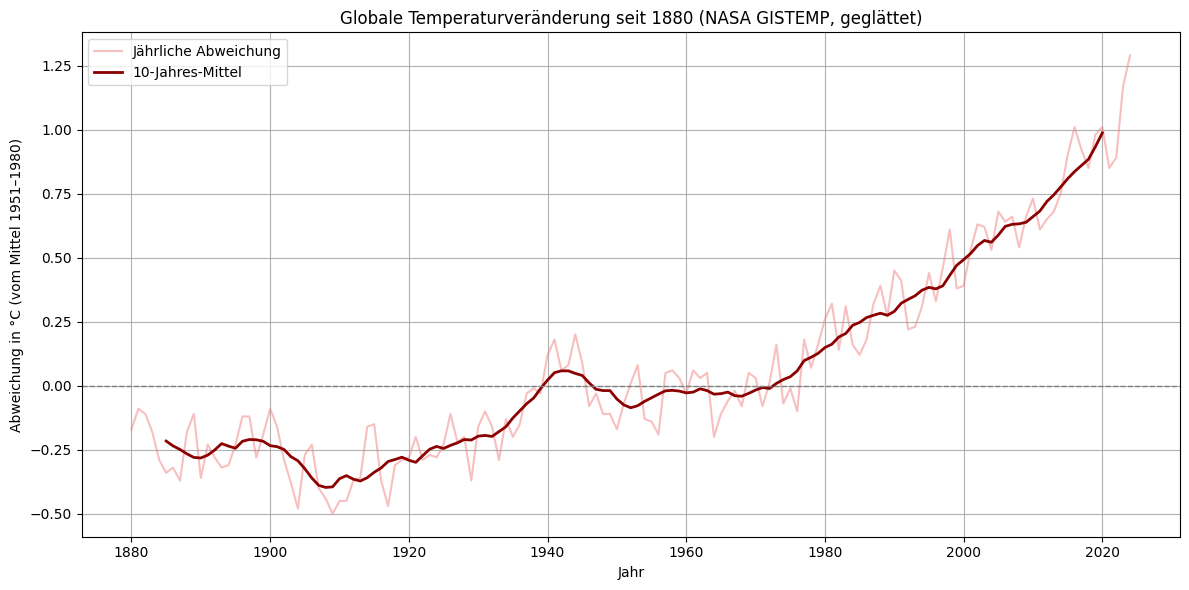

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV-Datei einlesen
df = pd.read_csv("data/nasa_temperature.csv", skiprows=1)

# Spaltennamen bereinigen
df.rename(columns={df.columns[0]: 'Year'}, inplace=True)
df = df[['Year', 'J-D']].dropna()
df['J-D'] = pd.to_numeric(df['J-D'], errors='coerce')

# Gleitenden Mittelwert berechnen (z. B. 10 Jahre)
df['Glättung'] = df['J-D'].rolling(window=10, center=True).mean()

# Plot erstellen
plt.figure(figsize=(12, 6))
plt.plot(df['Year'], df['J-D'], color='lightcoral', alpha=0.5, label='Jährliche Abweichung')
plt.plot(df['Year'], df['Glättung'], color='darkred', linewidth=2, label='10-Jahres-Mittel')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.title('Globale Temperaturveränderung seit 1880 (NASA GISTEMP, geglättet)')
plt.xlabel('Jahr')
plt.ylabel('Abweichung in °C (vom Mittel 1951–1980)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


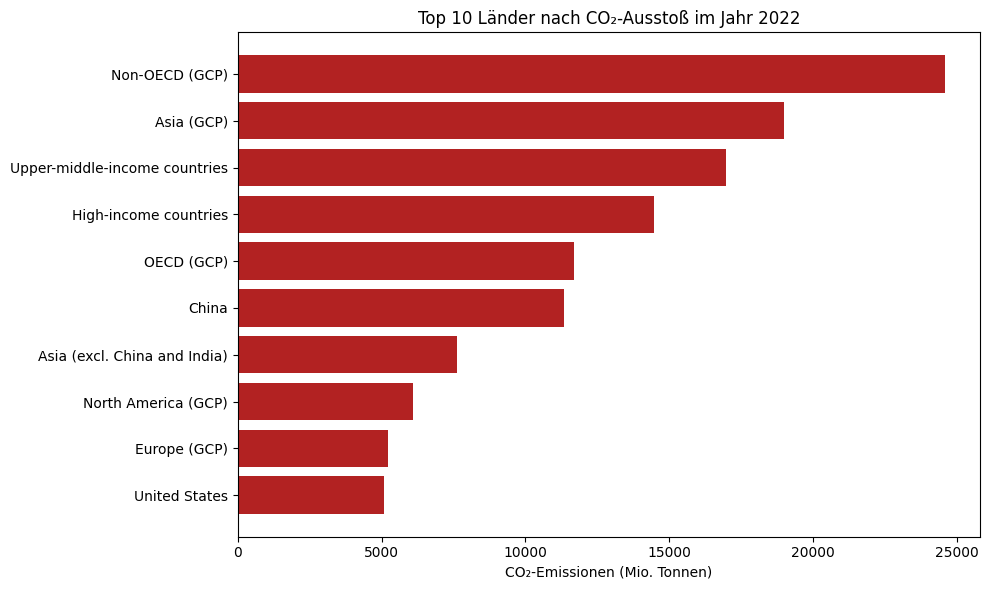

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Jahr festlegen
jahr = 2022

# Daten filtern
df_jahr = df[(df['year'] == jahr) & df['country'].notna() & df['co2'].notna()]

# Weltregionen entfernen
ausschliessen = ['World', 'Asia', 'Europe', 'Africa', 'Oceania',
                 'European Union', 'North America', 'South America', 'International transport']
df_jahr = df_jahr[~df_jahr['country'].isin(ausschliessen)]

# Top 10 Länder nach CO₂
top10 = df_jahr.sort_values(by='co2', ascending=False).head(10)

# Balkendiagramm erstellen
plt.figure(figsize=(10, 6))
plt.barh(top10['country'], top10['co2'], color='firebrick')
plt.xlabel('CO₂-Emissionen (Mio. Tonnen)')
plt.title(f'Top 10 Länder nach CO₂-Ausstoß im Jahr {jahr}')
plt.gca().invert_yaxis()  # höchste Werte oben
plt.tight_layout()
plt.show()


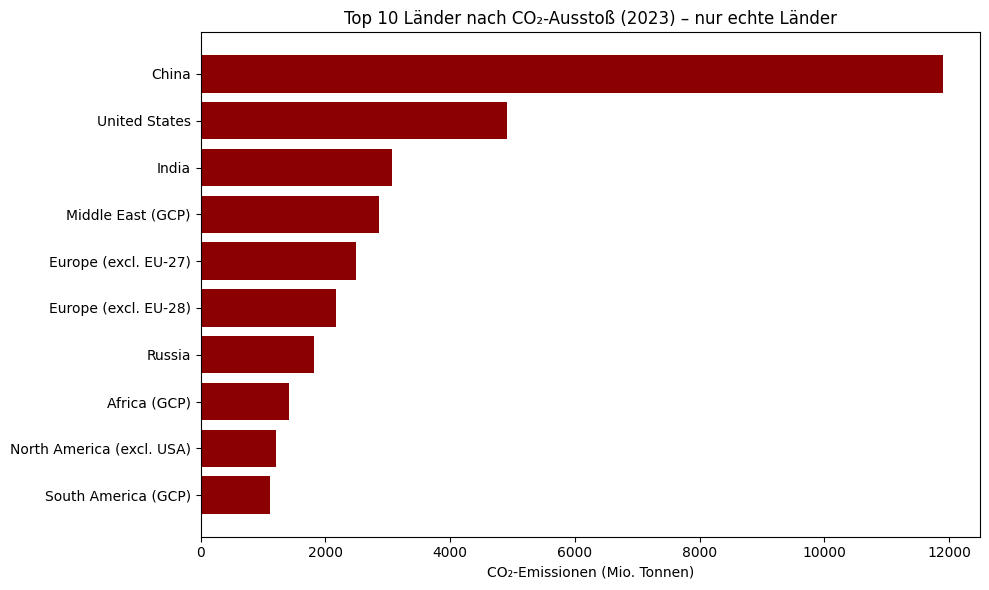

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Jahr wählen
jahr = 2023

# Liste der zu ignorierenden Einträge (keine echten Länder)
ausschliessen = [
    'World', 'Asia', 'Europe', 'Africa', 'Oceania', 'European Union',
    'North America', 'South America', 'International transport',
    'High-income countries', 'Low-income countries',
    'Lower-middle-income countries', 'Upper-middle-income countries',
    'European Union (27)', 'European Union (28)',
    'Non-OECD', 'OECD', 'Non-OECD (GCP)', 'OECD (GCP)', 'Asia (GCP)',
    'Asia (excl. China and India)', 'Europe (GCP)', 'North America (GCP)'
]


# Daten für das Jahr filtern
df_jahr = df[(df['year'] == jahr) & df['country'].notna() & df['co2'].notna()]
df_jahr = df_jahr[~df_jahr['country'].isin(ausschliessen)]

# Top 10 Länder nach CO₂-Emissionen
top10 = df_jahr.sort_values(by='co2', ascending=False).head(10)

# Balkendiagramm erstellen
plt.figure(figsize=(10, 6))
plt.barh(top10['country'], top10['co2'], color='darkred')
plt.xlabel('CO₂-Emissionen (Mio. Tonnen)')
plt.title(f'Top 10 Länder nach CO₂-Ausstoß ({jahr}) – nur echte Länder')
plt.gca().invert_yaxis()  # höchste Werte oben
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer (für Jupyter Notebook)
pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter: gültige Länder mit CO₂-Daten ab 1990
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

# Farbbereich beschränken (max. 98. Perzentil)
co2_max = df_anim['co2'].quantile(0.98)

# Choropleth-Animation
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale="Reds",
    range_color=(0, co2_max),  # Begrenzung der Skala für besseren Kontrast
    title="CO₂-Emissionen weltweit (1990 – aktuell)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer aktivieren
pio.renderers.default = "notebook_connected"

# CSV-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Daten filtern: ab 1900, gültige Ländercodes & CO₂-Werte
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

ampel_skala = [
    [0.0, "green"],     # Niedrig: Grün
    [0.5, "orange"],    # Mittel: Orange
    [1.0, "red"]        # Hoch: Rot
]


# Farbskala anpassen: max auf z.B. 5000 (statt automatisch auf 10000+)
# → damit bekommen mittlere Emittenten deutlich mehr Kontrast
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale= ampel_skala,
    range_color=(0, 10000),  # Feste obere Grenze für klareren Kontrast
    title="CO₂-Emissionen weltweit (1900–heute)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer aktivieren
pio.renderers.default = "notebook_connected"

# CSV-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Daten filtern: ab 1900, gültige Ländercodes & CO₂-Werte
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna()
]


# Farbskala anpassen: max auf z.B. 5000 (statt automatisch auf 10000+)
# → damit bekommen mittlere Emittenten deutlich mehr Kontrast
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale="Turbo",
    range_color=(0, 8000),  # Feste obere Grenze für klareren Kontrast
    title="CO₂-Emissionen weltweit (1900–heute)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer für Jupyter
pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter für Animation (ab 1900 oder je nach Datenbestand)
df_anim = df[
    (df['year'] >= 1900) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

# Choropleth mit MAGMA Farbverlauf und Maximalwert 5000
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale="Magma",   # Farbverlauf ähnlich wie dein Beispiel
    range_color=(0, 5000),            # auf 5000 Tonnen begrenzt
    title="CO₂-Emissionen weltweit (1950–heute, Skala bis 5000)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer für Jupyter
pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter für Animation (ab 1900 oder je nach Datenbestand)
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna()
]

fine_gradient = [
    [0.00, "#edf8fb"],   # sehr hellblau (niedrigste Werte)
    [0.03, "#b2e2e2"],  
    [0.05, "#66c2a4"],
    [0.10, "#2ca25f"], 
    [0.15, "#006d2c"],   # sattes Grün
    [0.50, "#fee08b"],   # gelblich
    [0.75, "#f46d43"],   # orange
    [0.90, "#d73027"],   # rot
    [1.00, "#7f0000"]    # dunkelrot
]



# Choropleth mit MAGMA Farbverlauf und Maximalwert 5000
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale=fine_gradient ,   # Farbverlauf ähnlich wie dein Beispiel
    range_color=(0, 7000),            # auf 5000 Tonnen begrenzt
    title="CO₂-Emissionen weltweit (1900–heute, Skala bis 5000)",
    labels={'co2': 'CO₂ (Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()


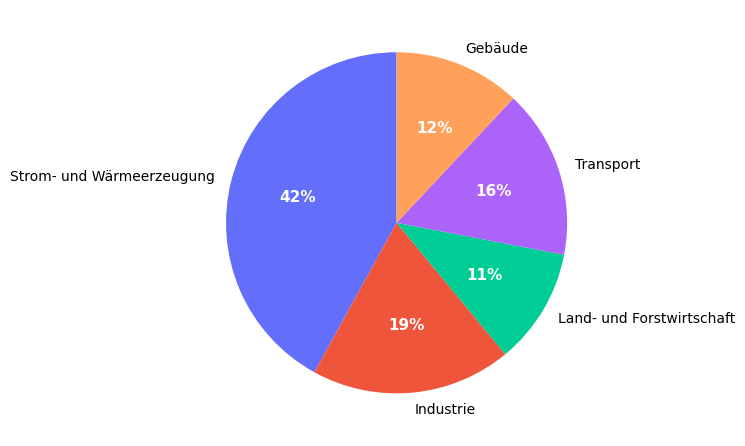

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Daten
bereiche = ["Strom- und Wärmeerzeugung", "Industrie", "Land- und Forstwirtschaft", "Transport", "Gebäude"]
prozent_werte = [42, 19, 11, 16, 12]  # Beispielhafte Werte in Prozent
farben = ['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A']  # Schönes Farbset

# Kreisdiagramm (klassisch, kein Donut)
fig, ax = plt.subplots()
wedges, texts = ax.pie(
    prozent_werte,
    labels=bereiche,
    colors=farben,
    startangle=90
)

# Prozentwerte mittig im jeweiligen Segment
for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.6 * np.cos(np.radians(ang))
    y = 0.6 * np.sin(np.radians(ang))
    ax.text(x, y, f"{prozent_werte[i]}%", ha='center', va='center', color='white', fontsize=11, weight='bold')

ax.set_aspect('equal')
plt.tight_layout()
plt.show()

In [ ]:
#Problem mit dieser Visualisierung. Kontinente werden nicht komplett gefärbt. Plotly ist dazu nicht fähig.
#Mögliche Lösung dazu: Länder gruppieren/ andere Visualisierungen

import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Liste der "Kontinent-Zeilen" in der country-Spalte
kontinente = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania"]

# Filter: nur diese, gültiges Jahr & CO2
df_kont = df[
    (df['country'].isin(kontinente)) &
    (df['year'] >= 1950) &
    (df['year'] <= 2023) &
    (df['co2'].notna())
]

# Manuelle Koordinaten für Kontinente
coords = {
    "Africa": {"lat": 1.6508, "lon": 17.6791},
    "Asia": {"lat": 34.0479, "lon": 100.6197},
    "Europe": {"lat": 54.5260, "lon": 15.2551},
    "North America": {"lat": 54.5260, "lon": -105.2551},
    "South America": {"lat": -8.7832, "lon": -55.4915},
    "Oceania": {"lat": -22.7359, "lon": 140.0188}
}

# Koordinaten einfügen
df_kont["lat"] = df_kont["country"].map(lambda x: coords[x]["lat"])
df_kont["lon"] = df_kont["country"].map(lambda x: coords[x]["lon"])

# Bubble-Map Animation
fig = px.scatter_geo(
    df_kont,
    lat="lat",
    lon="lon",
    size="co2",
    color="co2",
    hover_name="country",
    animation_frame="year",
    projection="natural earth",
    color_continuous_scale="Magma",
    range_color=(0, 5000),
    title="CO₂-Emissionen pro Kontinent (1950–2023)",
    labels={"co2": "CO₂ (Mio. Tonnen)"}
)

fig.update_layout(
    geo=dict(showframe=False, showcoastlines=True),
    margin={"r":0,"t":40,"l":0,"b":0}
)

fig.show()

/var/folders/z0/jrzdsfjn007ckvbmtm_81l8r0000gn/T/ipykernel_1353/1359412598.py:35: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/z0/jrzdsfjn007ckvbmtm_81l8r0000gn/T/ipykernel_1353/1359412598.py:36: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



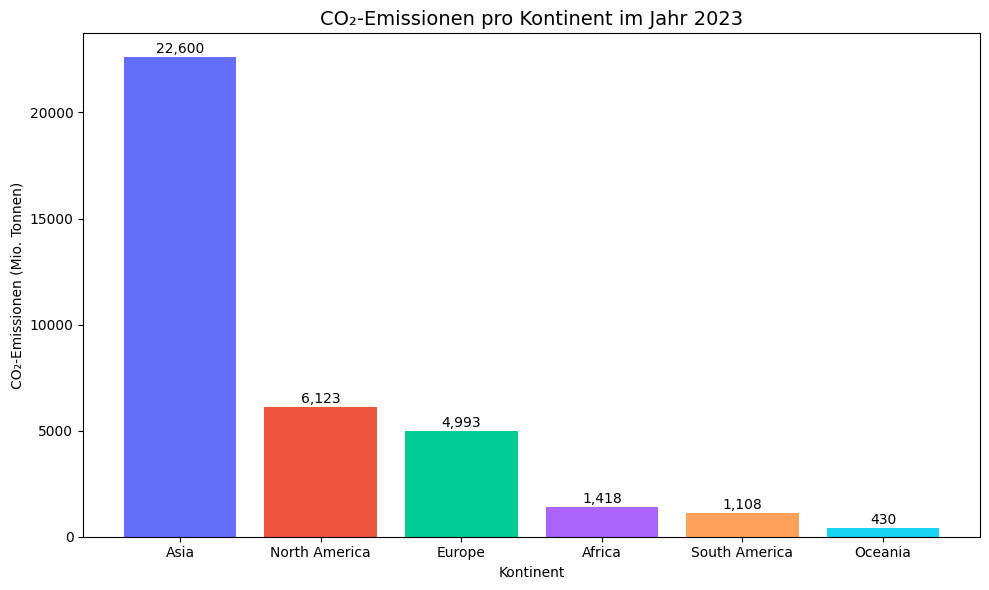

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Zieljahr
jahr = 2023

# Kontinente, wie sie im Datensatz stehen
kontinente = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania"]

# Filtern: nur diese Kontinente und gültige CO₂-Daten
df_kont = df[
    (df['year'] == jahr) &
    (df['country'].isin(kontinente)) &
    (df['co2'].notna())
]

# Sortieren nach CO₂-Ausstoß
df_kont = df_kont.sort_values(by='co2', ascending=False)

# Balkendiagramm
farben = ['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A', '#19D3F3']
plt.figure(figsize=(10, 6))
bars = plt.bar(df_kont['country'], df_kont['co2'], color=farben)

# Achsenbeschriftung und Titel
plt.title("CO₂-Emissionen pro Kontinent im Jahr 2023", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("CO₂-Emissionen (Mio. Tonnen)")

# Zahlen direkt über den Balken anzeigen
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{int(yval):,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


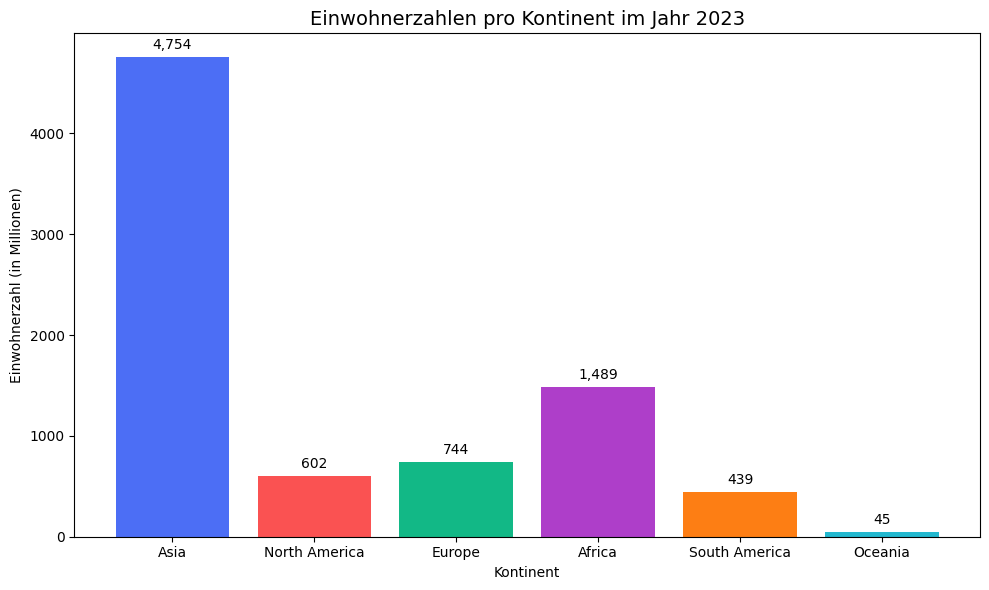

In [ ]:
import matplotlib.pyplot as plt

# Daten: Bevölkerung in Millionen (2023, gerundet)
kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]
einwohner_mio = [4754, 602, 744, 1489, 439, 45]

# Farben wie im CO₂-Diagramm
farben = {
    "Asia": "#4c6ef5",
    "North America": "#fa5252",
    "Europe": "#12b886",
    "Africa": "#ae3ec9",
    "South America": "#fd7e14",
    "Oceania": "#22b8cf"
}

farben_liste = [farben[k] for k in kontinente]

# Plot
plt.figure(figsize=(10, 6))
bars = plt.bar(kontinente, einwohner_mio, color=farben_liste)

# Beschriftung
plt.title("Einwohnerzahlen pro Kontinent im Jahr 2023", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("Einwohnerzahl (in Millionen)")

# Werte anzeigen
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{yval:,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


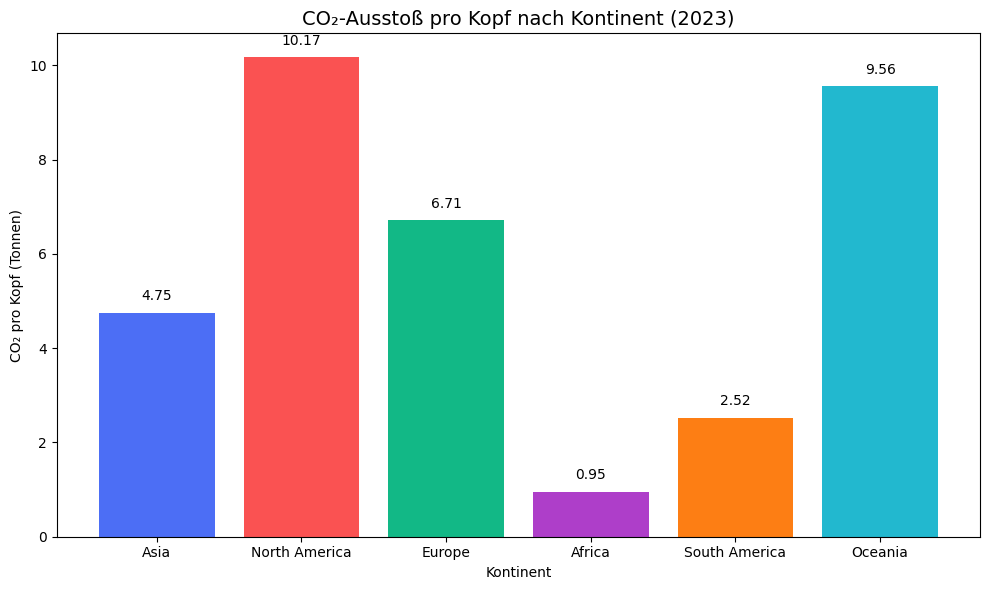

In [ ]:
import matplotlib.pyplot as plt

# Daten
kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]
co2_mio_tonnen = [22600, 6123, 4993, 1418, 1108, 430]
einwohner_mio = [4754, 602, 744, 1489, 439, 45]

# CO₂ pro Kopf berechnen (in Tonnen)
co2_pro_kopf = [co2 / bev for co2, bev in zip(co2_mio_tonnen, einwohner_mio)]

# Farben (gleich wie vorher)
farben = {
    "Asia": "#4c6ef5",
    "North America": "#fa5252",
    "Europe": "#12b886",
    "Africa": "#ae3ec9",
    "South America": "#fd7e14",
    "Oceania": "#22b8cf"
}
farben_liste = [farben[k] for k in kontinente]

# Plot
plt.figure(figsize=(10, 6))
bars = plt.bar(kontinente, co2_pro_kopf, color=farben_liste)

# Beschriftung
plt.title("CO₂-Ausstoß pro Kopf nach Kontinent (2023)", fontsize=14)
plt.xlabel("Kontinent")
plt.ylabel("CO₂ pro Kopf (Tonnen)")

# Werte anzeigen
for bar, val in zip(bars, co2_pro_kopf):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.2, f"{val:.2f}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


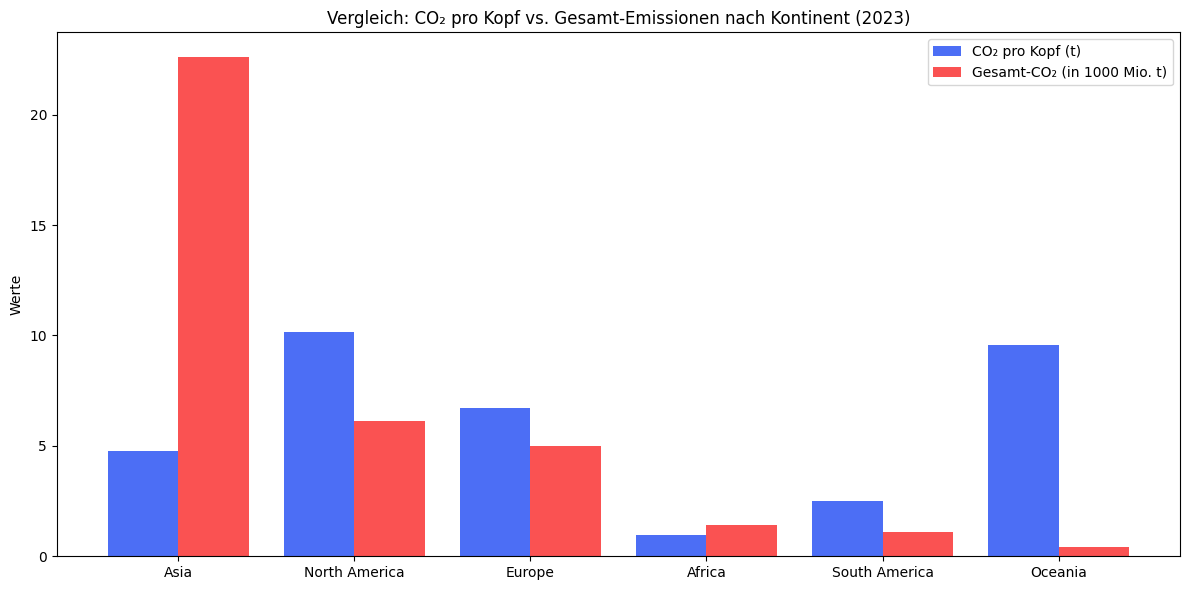

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Kontinente
kontinente = ["Asia", "North America", "Europe", "Africa", "South America", "Oceania"]

# Daten
co2_mio = [22600, 6123, 4993, 1418, 1108, 430]
bev_mio = [4754, 602, 744, 1489, 439, 45]
co2_pro_kopf = [co2 / bev for co2, bev in zip(co2_mio, bev_mio)]

# Balkenhöhen skalieren, damit man sie gemeinsam zeigen kann (hier: Gesamt durch 1000)
co2_mio_skaliert = [v / 1000 for v in co2_mio]  # z. B. "in 1000 Mio. Tonnen"

x = np.arange(len(kontinente))
width = 0.4

# Plot
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, co2_pro_kopf, width, label="CO₂ pro Kopf (t)", color="#4c6ef5")
plt.bar(x + width/2, co2_mio_skaliert, width, label="Gesamt-CO₂ (in 1000 Mio. t)", color="#fa5252")

# Achsen & Beschriftung
plt.xticks(x, kontinente)
plt.ylabel("Werte")
plt.title("Vergleich: CO₂ pro Kopf vs. Gesamt-Emissionen nach Kontinent (2023)")
plt.legend()
plt.tight_layout()
plt.show()


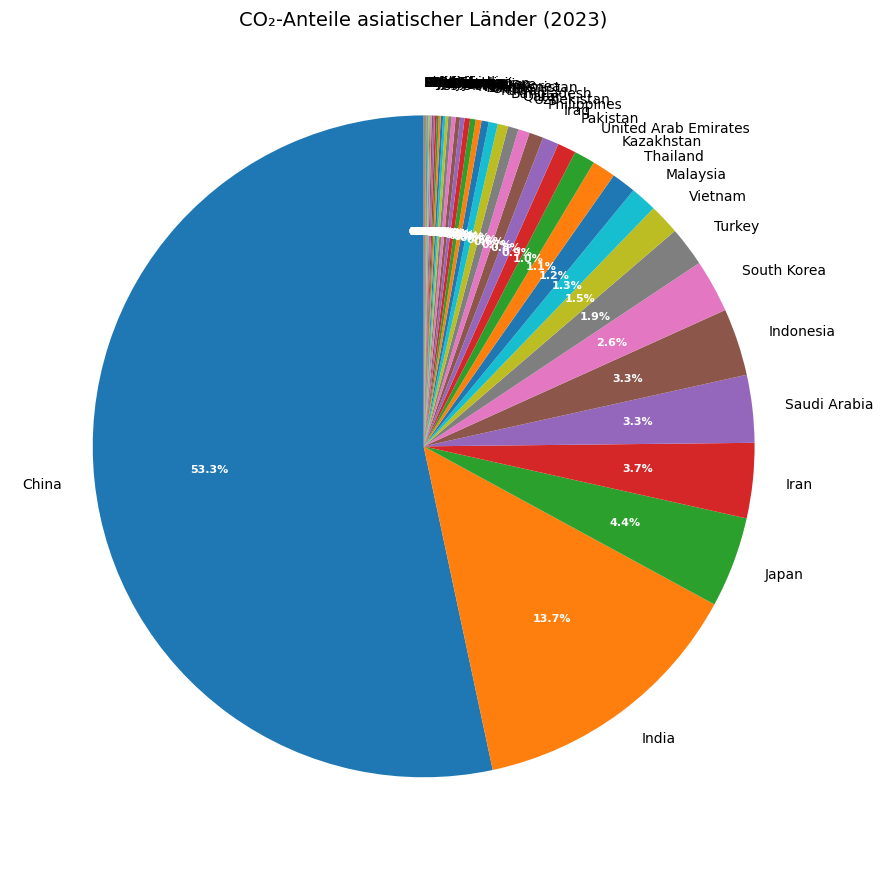

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Jahr
jahr = 2023

# Manuell definierte asiatische Länder aus deiner Liste
asiatische_laender = [
    "Afghanistan", "Armenia", "Azerbaijan", "Bahrain", "Bangladesh", "Bhutan", "Brunei",
    "Cambodia", "China", "Cyprus", "East Timor", "Georgia", "India", "Indonesia", "Iran", "Iraq",
    "Israel", "Japan", "Jordan", "Kazakhstan", "Kuwait", "Kyrgyzstan", "Laos", "Lebanon", "Malaysia",
    "Maldives", "Mongolia", "Myanmar", "Nepal", "North Korea", "Oman", "Pakistan", "Palestine",
    "Philippines", "Qatar", "Saudi Arabia", "Singapore", "South Korea", "Sri Lanka", "Syria",
    "Tajikistan", "Thailand", "Turkey", "Turkmenistan", "United Arab Emirates", "Uzbekistan",
    "Vietnam", "Yemen"
]

# Filter auf diese Länder im gewünschten Jahr
df_asien = df[
    (df['year'] == jahr) &
    (df['country'].isin(asiatische_laender)) &
    (df['co2'].notna())
]

# Sortieren nach CO₂-Ausstoß
df_asien = df_asien.sort_values(by='co2', ascending=False)

# Werte für Pie Chart
labels = df_asien['country']
werte = df_asien['co2']
gesamt = werte.sum()
prozent = [f"{(v / gesamt * 100):.1f}%" for v in werte]

# Pie Chart
fig, ax = plt.subplots(figsize=(9, 9))
wedges, texts = ax.pie(werte, labels=labels, startangle=90)

# Prozentwerte innen einfügen
for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.65 * np.cos(np.radians(ang))
    y = 0.65 * np.sin(np.radians(ang))
    ax.text(x, y, prozent[i], ha='center', va='center', fontsize=8, color='white', weight='bold')

# Titel
plt.title("CO₂-Anteile asiatischer Länder (2023)", fontsize=14)
plt.tight_layout()
plt.show()


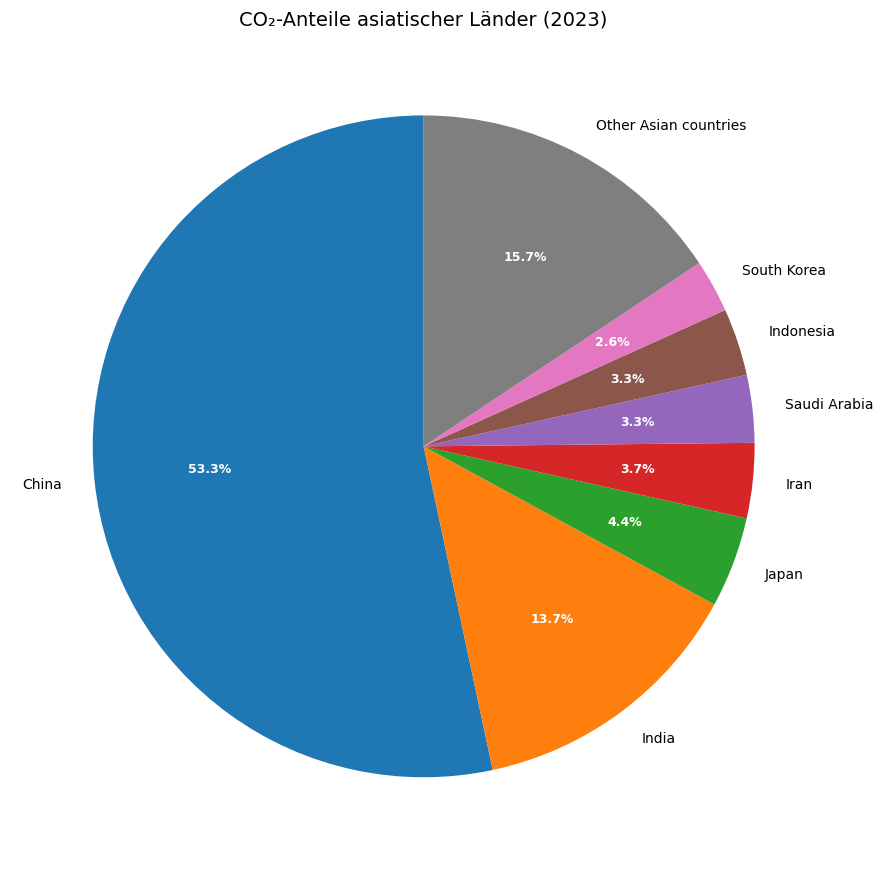

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Jahr
jahr = 2023

# Liste aller asiatischen Länder
asiatische_laender = [
    "Afghanistan", "Armenia", "Azerbaijan", "Bahrain", "Bangladesh", "Bhutan", "Brunei",
    "Cambodia", "China", "Cyprus", "East Timor", "Georgia", "India", "Indonesia", "Iran", "Iraq",
    "Israel", "Japan", "Jordan", "Kazakhstan", "Kuwait", "Kyrgyzstan", "Laos", "Lebanon", "Malaysia",
    "Maldives", "Mongolia", "Myanmar", "Nepal", "North Korea", "Oman", "Pakistan", "Palestine",
    "Philippines", "Qatar", "Saudi Arabia", "Singapore", "South Korea", "Sri Lanka", "Syria",
    "Tajikistan", "Thailand", "Turkey", "Turkmenistan", "United Arab Emirates", "Uzbekistan",
    "Vietnam", "Yemen"
]

# Filter & sortieren
df_asien = df[
    (df['year'] == jahr) &
    (df['country'].isin(asiatische_laender)) &
    (df['co2'].notna())
].copy()

# Gesamtmenge
gesamt = df_asien['co2'].sum()

# Prozentanteile berechnen
df_asien['anteil'] = df_asien['co2'] / gesamt * 100

# Split: große Länder vs. "Other Asian Countries"
df_top = df_asien[df_asien['anteil'] >= 2].sort_values(by='co2', ascending=False)
df_rest = df_asien[df_asien['anteil'] < 2]

# "Other Asian Countries" summieren
other_sum = df_rest['co2'].sum()
other_anteil = other_sum / gesamt * 100

# Neue Zeile für "Other Asian Countries"
df_other = pd.DataFrame({
    'country': ['Other Asian countries'],
    'co2': [other_sum],
    'anteil': [other_anteil]
})

# Kombinieren
df_pie = pd.concat([df_top, df_other], ignore_index=True)

# Kreisdiagramm
labels = df_pie['country']
werte = df_pie['co2']
prozent = [f"{(v / gesamt * 100):.1f}%" for v in werte]

fig, ax = plt.subplots(figsize=(9, 9))
wedges, texts = ax.pie(werte, labels=labels, startangle=90)

# Prozentwerte einfügen
for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.65 * np.cos(np.radians(ang))
    y = 0.65 * np.sin(np.radians(ang))
    ax.text(x, y, prozent[i], ha='center', va='center', fontsize=9, color='white', weight='bold')

plt.title("CO₂-Anteile asiatischer Länder (2023)", fontsize=14)
plt.tight_layout()
plt.show()


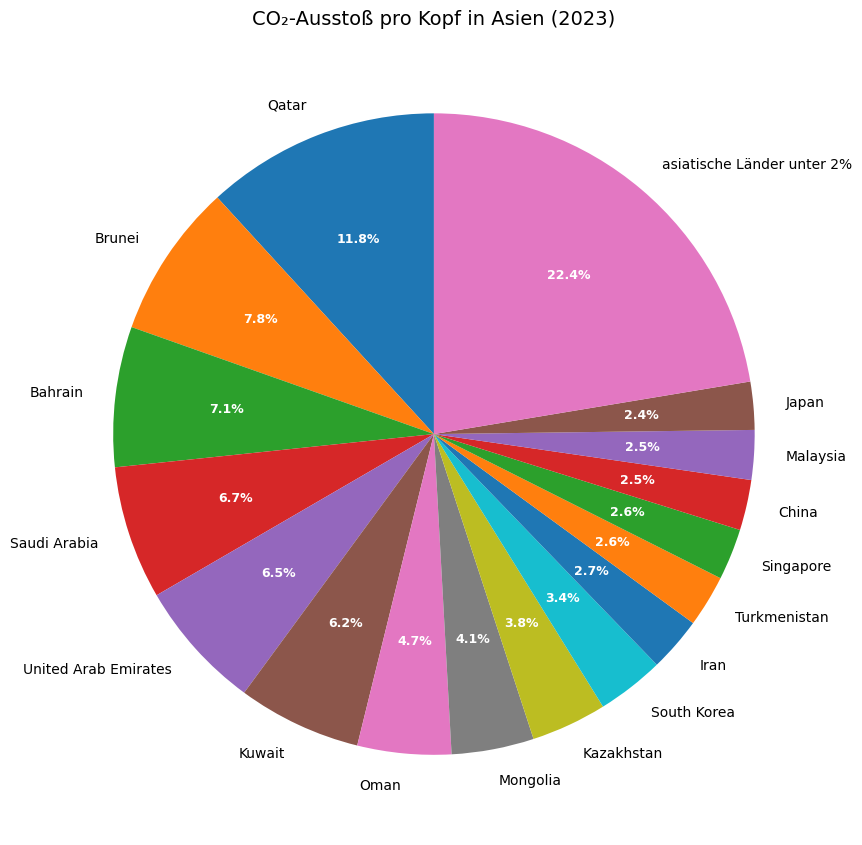

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

jahr = 2023

asiatische_laender = [
    "Afghanistan", "Armenia", "Azerbaijan", "Bahrain", "Bangladesh", "Bhutan", "Brunei",
    "Cambodia", "China", "Cyprus", "East Timor", "Georgia", "India", "Indonesia", "Iran", "Iraq",
    "Israel", "Japan", "Jordan", "Kazakhstan", "Kuwait", "Kyrgyzstan", "Laos", "Lebanon", "Malaysia",
    "Maldives", "Mongolia", "Myanmar", "Nepal", "North Korea", "Oman", "Pakistan", "Palestine",
    "Philippines", "Qatar", "Saudi Arabia", "Singapore", "South Korea", "Sri Lanka", "Syria",
    "Tajikistan", "Thailand", "Turkey", "Turkmenistan", "United Arab Emirates", "Uzbekistan",
    "Vietnam", "Yemen"
]

# Filter auf asiatische Länder mit gültigen Pro-Kopf-Werten
df_asien = df[
    (df['year'] == jahr) &
    (df['country'].isin(asiatische_laender)) &
    (df['co2_per_capita'].notna())
].copy()

# Summe aller Pro-Kopf-Werte (für Verteilung, nicht absolute Masse!)
gesamt = df_asien['co2_per_capita'].sum()

# Anteile berechnen
df_asien['anteil'] = df_asien['co2_per_capita'] / gesamt * 100

# Trennen in Top-Länder und Rest
df_top = df_asien[df_asien['anteil'] >= 2].sort_values(by='co2_per_capita', ascending=False)
df_rest = df_asien[df_asien['anteil'] < 2]

# "Other Asian countries"
other_sum = df_rest['co2_per_capita'].sum()
other_anteil = other_sum / gesamt * 100

df_other = pd.DataFrame({
    'country': ['asiatische Länder unter 2%'],
    'co2_per_capita': [other_sum],
    'anteil': [other_anteil]
})

df_pie = pd.concat([df_top[['country', 'co2_per_capita', 'anteil']], df_other], ignore_index=True)

# Pie Chart
labels = df_pie['country']
werte = df_pie['co2_per_capita']
prozent = [f"{(v / gesamt * 100):.1f}%" for v in werte]

fig, ax = plt.subplots(figsize=(9, 9))
wedges, texts = ax.pie(werte, labels=labels, startangle=90)

# Prozentwerte
for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2
    x = 0.65 * np.cos(np.radians(ang))
    y = 0.65 * np.sin(np.radians(ang))
    ax.text(x, y, prozent[i], ha='center', va='center', fontsize=9, color='white', weight='bold')

plt.title("CO₂-Ausstoß pro Kopf in Asien (2023)", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import plotly.express as px

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Nur echte Länder mit CO₂-Wert und ISO-Code
df_länder = df[
    (df['year'] == 2023) &
    (df['iso_code'].notna()) &
    (df['co2'].notna())
].copy()

# Manuelles Mapping: country → continent
kontinent_map = {
    "China": "Asia", "India": "Asia", "Japan": "Asia", "Indonesia": "Asia", "Iran": "Asia",
    "Saudi Arabia": "Asia", "South Korea": "Asia", "Vietnam": "Asia", "Thailand": "Asia", "Singapore": "Asia",
    "Russia": "Europe", "Germany": "Europe", "France": "Europe", "United Kingdom": "Europe",
    "Italy": "Europe", "Spain": "Europe", "Poland": "Europe", "Ireland": "Europe", "Switzerland": "Europe",
    "United States": "North America", "Canada": "North America", "Mexico": "North America",
    "Brazil": "South America", "Argentina": "South America", "Colombia": "South America",
    "South Africa": "Africa", "Egypt": "Africa", "Nigeria": "Africa",
    "Australia": "Oceania", "New Zealand": "Oceania"
}

# Mapping anwenden
df_länder["continent"] = df_länder["country"].map(kontinent_map)
df_länder = df_länder[df_länder["continent"].notna()]

# Benutzerdefinierte Farben
custom_colors = {
    "Asia": "#e74c3c",           # rot
    "Europe": "#f1c40f",         # gelb
    "North America": "#3498db", # blau
    "South America": "#5dade2", # hellblau
    "Africa": "#58d68d",        # grün
    "Oceania": "#8e44ad"        # violett
}

# Sunburst zeichnen
fig = px.sunburst(
    df_länder,
    path=["continent", "country"],
    values="co2",
    color="continent",
    color_discrete_map=custom_colors,
    title="🌍 CO₂-Ausstoß nach Kontinent und Land (2023)"
)

fig.update_layout(margin=dict(t=50, l=0, r=0, b=0))
fig.show()

# Logarithmische scale

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter für Animation (ab 1900 oder je nach Datenbestand)
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2'].notna() &
    (df['co2'] > 0)  # nur positive Werte, da log10(0) nicht definiert ist
].copy()

fine_gradient = [
    [0.00, "#edf8fb"],   # sehr hellblau (niedrigste Werte)
    [0.03, "#b2e2e2"],  
    [0.05, "#66c2a4"],
    [0.10, "#2ca25f"], 
    [0.15, "#006d2c"],   # sattes Grün
    [0.50, "#fee08b"],   # gelblich
    [0.75, "#f46d43"],   # orange
    [0.90, "#d73027"],   # rot
    [1.00, "#7f0000"]    # dunkelrot
]


# Neue Spalte: Logarithmus der CO2-Emissionen
df_anim['log_co2'] = np.log10(df_anim['co2'])

# Choropleth mit log10-Skalierung
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="log_co2",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale= fine_gradient,
    title="CO₂-Emissionen weltweit (1950–heute, logarithmische Skala)",
    labels={'log_co2': 'log₁₀(CO₂ in Mio. Tonnen)'}
)

fig.update_layout(
    margin={"r":0, "t":40, "l":0, "b":0}
)

fig.show()


# Pro Kopf

In [ ]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Plotly-Renderer für Jupyter
pio.renderers.default = "notebook_connected"

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter für Animation
df_anim = df[
    (df['year'] >= 1950) &
    df['iso_code'].notna() &
    df['co2_per_capita'].notna()
]

# Farbskala wie in deinem Beispiel
fine_gradient = [
    [0.00, "#edf8fb"],
    [0.03, "#b2e2e2"],
    [0.05, "#66c2a4"],
    [0.10, "#2ca25f"],
    [0.15, "#006d2c"],
    [0.50, "#fee08b"],
    [0.75, "#f46d43"],
    [0.90, "#d73027"],
    [1.00, "#7f0000"]
]

# Choropleth: CO₂ pro Kopf
fig = px.choropleth(
    df_anim,
    locations="iso_code",
    color="co2_per_capita",
    hover_name="country",
    animation_frame="year",
    color_continuous_scale=fine_gradient,
    range_color=(0, 25),  # typische Pro-Kopf-Werte
    title="CO₂-Ausstoß pro Kopf weltweit (1950–heute)",
    labels={'co2_per_capita': 'CO₂ pro Kopf (t)'}
)

fig.update_layout(
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)

fig.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Länder auswählen
laender = ['Germany', 'United States', 'China', 'Russia']
df_laender = df[df['country'].isin(laender)]

# Jahr einschränken
startjahr = 1950
df_laender = df_laender[df_laender['year'] >= startjahr]

# Plot: CO₂ pro Kopf
plt.figure(figsize=(12, 6))
for land in laender:
    daten_land = df_laender[df_laender['country'] == land]
    plt.plot(daten_land['year'], daten_land['co2_per_capita'], label=land)

plt.title(f'CO₂-Emissionen pro Kopf ab {startjahr}')
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Person (Tonnen)')
plt.legend()
plt.grid


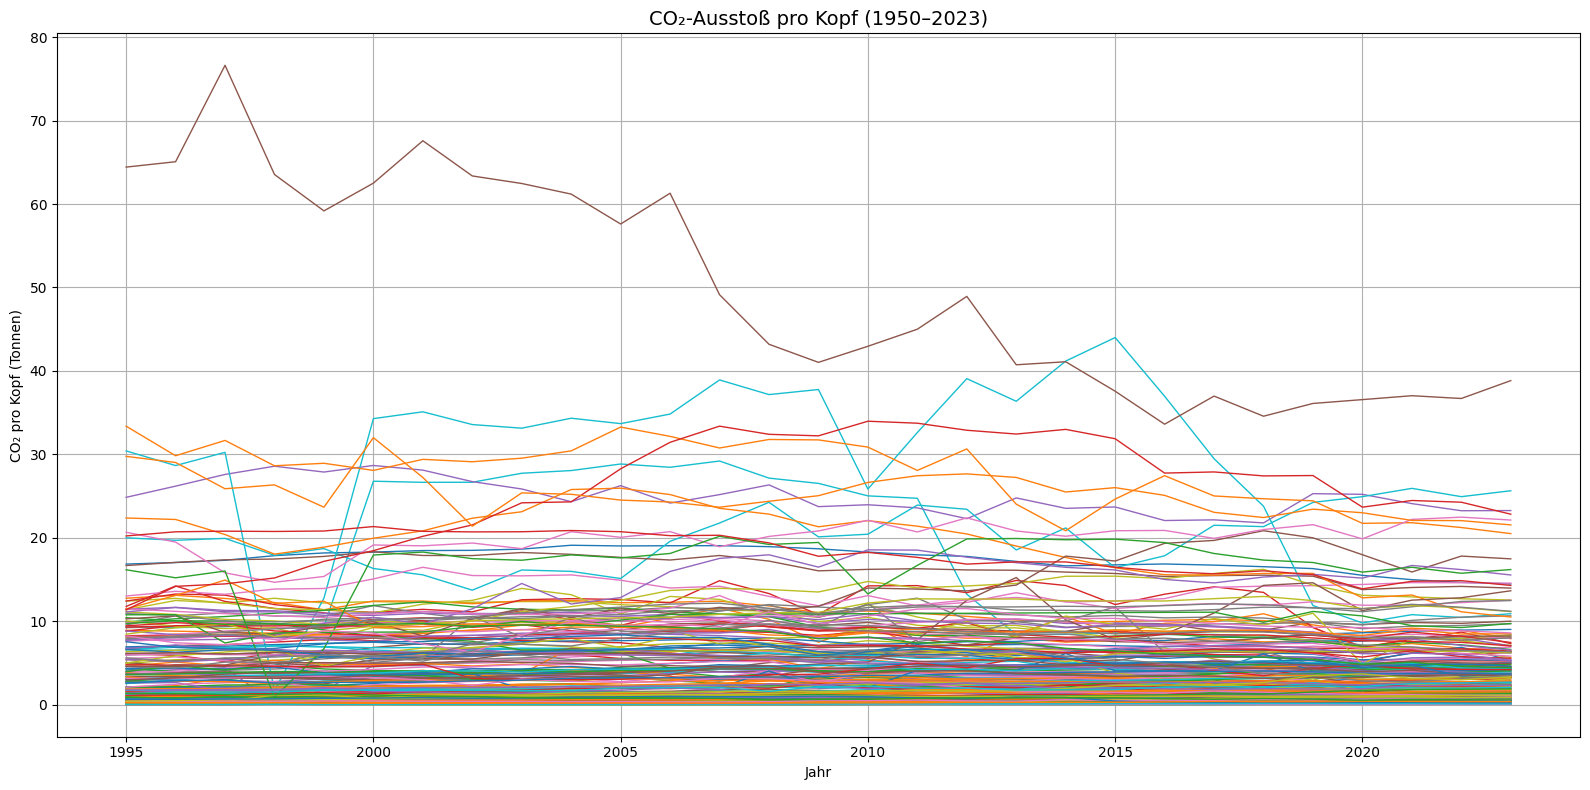

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV einlesen
df = pd.read_csv("data/owid-co2-data.csv")

# Nur echte Länder mit gültigen Werten ab 1950
df = df[
    (df['year'] >= 1995) &
    (df['iso_code'].notna()) &
    (df['co2_per_capita'].notna())
]

# Plot vorbereiten
plt.figure(figsize=(16, 8))

# Jede Linie bekommt eine eigene Farbe
for country in df['country'].unique():
    df_land = df[df['country'] == country]
    plt.plot(df_land['year'], df_land['co2_per_capita'], label=country, linewidth=1)

# Beschriftung
plt.title('CO₂-Ausstoß pro Kopf (1950–2023)', fontsize=14)
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Kopf (Tonnen)')

# Optional: Legende deaktivieren (oder interaktiv in Jupyter verwenden)
# plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize='small', ncol=2)
plt.tight_layout()
plt.grid(True)
plt.show()


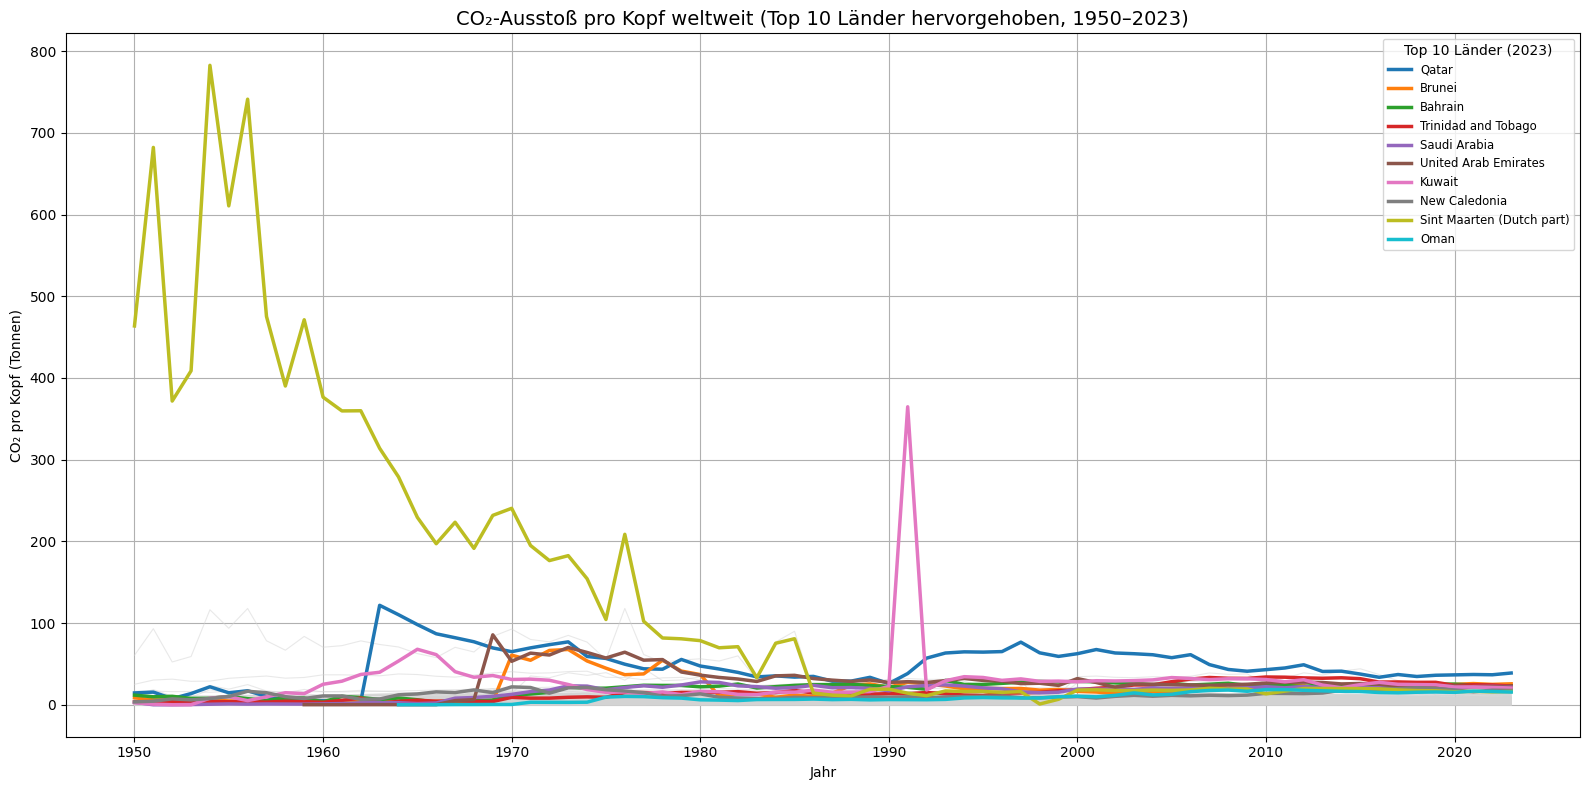

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Daten filtern
df = df[
    (df['year'] >= 1950) &
    (df['iso_code'].notna()) &
    (df['co2_per_capita'].notna())
]

# Top 10 Länder mit höchstem CO₂ pro Kopf im Jahr 2023
df_2023 = df[df['year'] == 2023]

top10 = df_2023.sort_values(by='co2_per_capita', ascending=False).head(10)['country'].tolist()

# Plot vorbereiten
plt.figure(figsize=(16, 8))

# Alle Länder grau zeichnen
for country in df['country'].unique():
    df_land = df[df['country'] == country]
    if country not in top10:
        plt.plot(df_land['year'], df_land['co2_per_capita'], color='lightgray', linewidth=0.8, alpha=0.5)

# Farben für Top 10
farben = plt.cm.tab10.colors  # 10 bunte Farben

# Top 10 Länder farbig hervorheben
for i, country in enumerate(top10):
    df_land = df[df['country'] == country]
    plt.plot(df_land['year'], df_land['co2_per_capita'], label=country, linewidth=2.5, color=farben[i % len(farben)])


# Achsen, Titel, Legende
plt.title('CO₂-Ausstoß pro Kopf weltweit (Top 10 Länder hervorgehoben, 1950–2023)', fontsize=14)
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Kopf (Tonnen)')
plt.legend(title="Top 10 Länder (2023)", fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()


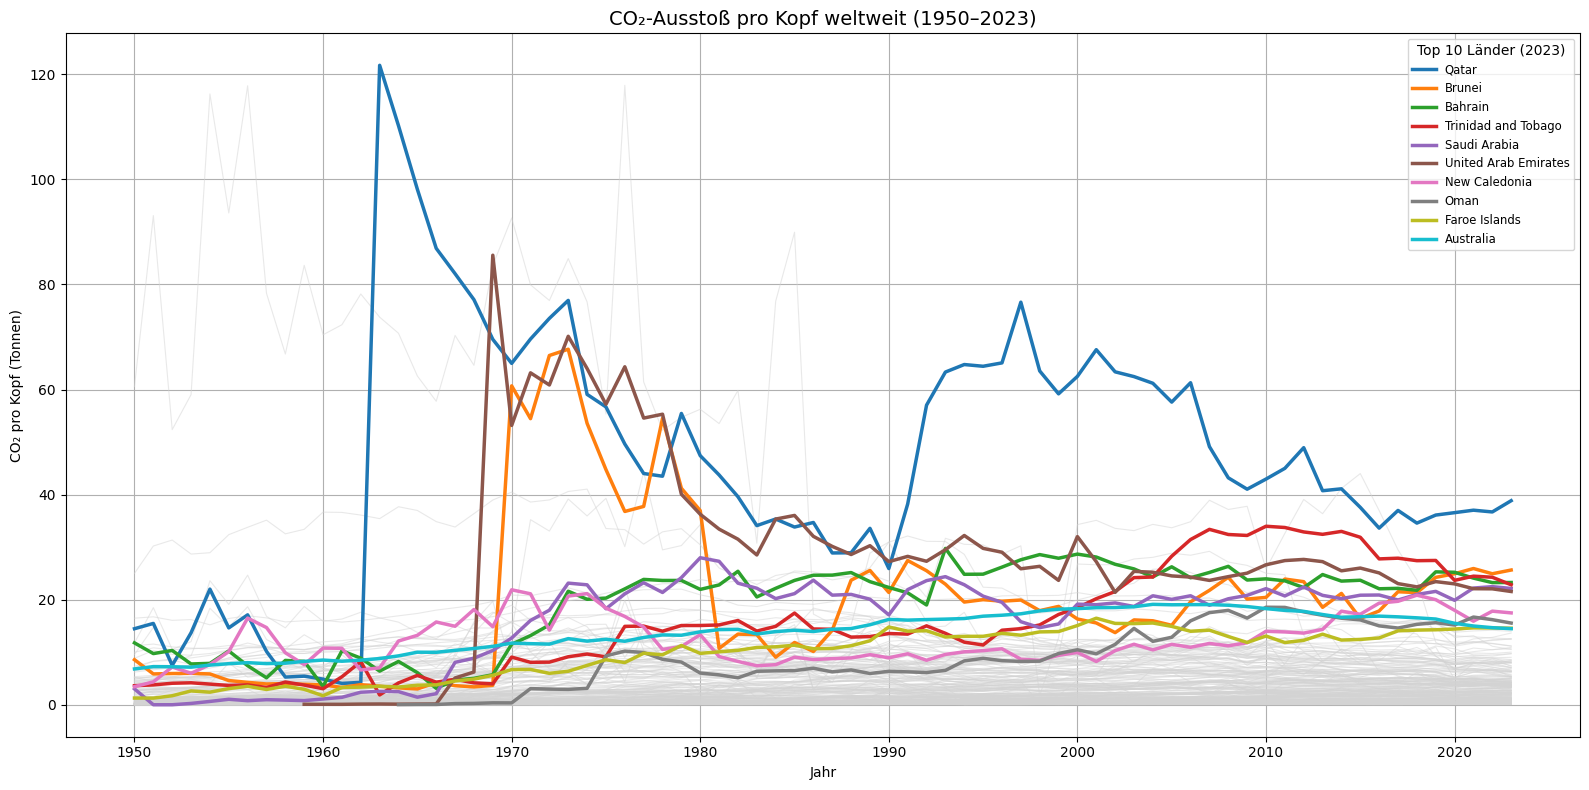

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Länder ausschließen
ausnahmen = ["Kuwait", "Sint Maarten (Dutch part)"]

# Daten filtern
df = df[
    (df['year'] >= 1950) &
    (df['iso_code'].notna()) &
    (df['co2_per_capita'].notna()) &
    (~df['country'].isin(ausnahmen))
]

# Top 10 Länder mit höchstem CO₂ pro Kopf im Jahr 2023 (nach Ausschluss)
df_2023 = df[df['year'] == 2023]
top10 = df_2023.sort_values(by='co2_per_capita', ascending=False).head(10)['country'].tolist()

# Plot vorbereiten
plt.figure(figsize=(16, 8))

# Alle Länder grau zeichnen
for country in df['country'].unique():
    df_land = df[df['country'] == country]
    if country not in top10:
        plt.plot(df_land['year'], df_land['co2_per_capita'], color='lightgray', linewidth=0.8, alpha=0.5)

# Farben für Top 10
farben = plt.cm.tab10.colors  # 10 bunte Farben

# Top 10 Länder farbig hervorheben
for i, country in enumerate(top10):
    df_land = df[df['country'] == country]
    plt.plot(df_land['year'], df_land['co2_per_capita'], label=country, linewidth=2.5, color=farben[i % len(farben)])

# Achsen, Titel, Legende
plt.title('CO₂-Ausstoß pro Kopf weltweit (1950–2023)', fontsize=14)
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Kopf (Tonnen)')
plt.legend(title="Top 10 Länder (2023)", fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()



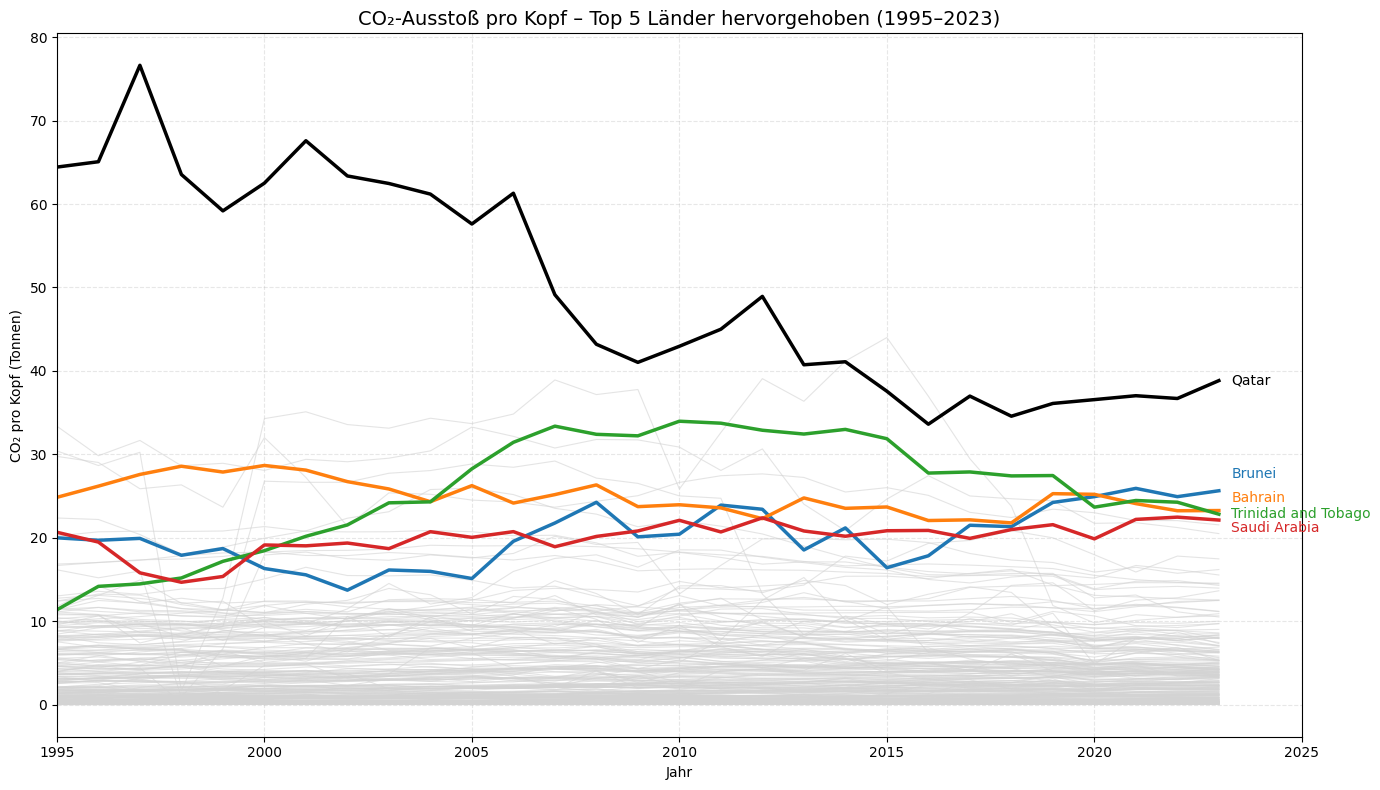

In [4]:
import pandas as pd
import matplotlib.pyplot as plt


# CSV laden
df = pd.read_csv("data/owid-co2-data.csv")

# Filter: gültige Daten & Zeitraum
df = df[
    (df['year'] >= 1995) &
    df['iso_code'].notna() &
    df['co2_per_capita'].notna()
]

# Top 5 Länder mit höchstem CO₂ pro Kopf 2023
top5 = df[df['year'] == 2023].sort_values(by='co2_per_capita', ascending=False).head(5)['country'].tolist()

# Farben für Top 5
farben = ['#000000', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Schwarz, Blau, Orange, Grün, Rot
farb_dict = dict(zip(top5, farben))

# Plot vorbereiten
plt.figure(figsize=(14, 8))

# Alle Länder grau zeichnen
for country in df['country'].unique():
    df_land = df[df['country'] == country]
    if country not in top5:
        plt.plot(df_land['year'], df_land['co2_per_capita'], color='lightgray', linewidth=0.8, alpha=0.6)

# Top 5 Länder farbig & mit Name am Ende
for country in top5:
    df_land = df[df['country'] == country]
    plt.plot(df_land['year'], df_land['co2_per_capita'], linewidth=2.5, color=farb_dict[country])

    offsets = {
    'Qatar': 0,
    'Brunei': 2,
    'Trinidad and Tobago': 0,
    'Bahrain': 1.5,
    'Saudi Arabia': -1
}
    
    # Ländername am rechten Rand
    x = df_land['year'].max()
    y = df_land[df_land['year'] == x]['co2_per_capita'].values[0]
    plt.text(x + 0.3, y + offsets.get(country, 0), country, fontsize=10, color=farb_dict[country], va='center')



# Titel & Achsen
plt.title('CO₂-Ausstoß pro Kopf – Top 5 Länder hervorgehoben (1995–2023)', fontsize=14)
plt.xlabel('Jahr')
plt.ylabel('CO₂ pro Kopf (Tonnen)')
plt.xlim(1995, 2025)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import plotly.express as px

# CO₂-Daten laden
df = pd.read_csv("data/owid-co2-data.csv")

# Nur echte Länder im Jahr 2023
df_länder = df[
    (df['year'] == 2023) &
    (df['iso_code'].notna()) &
    (df['co2'].notna())
].copy()

# Manuelles Mapping: country → continent
kontinent_map = {
    "China": "Asia", "India": "Asia", "Japan": "Asia", "Indonesia": "Asia", "Iran": "Asia",
    "Saudi Arabia": "Asia", "South Korea": "Asia", "Vietnam": "Asia", "Thailand": "Asia", "Singapore": "Asia",
    "Russia": "Europe", "Germany": "Europe", "France": "Europe", "United Kingdom": "Europe",
    "Italy": "Europe", "Spain": "Europe", "Poland": "Europe", "Ireland": "Europe", "Switzerland": "Europe",
    "United States": "North America", "Canada": "North America", "Mexico": "North America",
    "Brazil": "South America", "Argentina": "South America", "Colombia": "South America",
    "South Africa": "Africa", "Egypt": "Africa", "Nigeria": "Africa",
    "Australia": "Oceania", "New Zealand": "Oceania"
}

# Mapping anwenden
df_länder["continent"] = df_länder["country"].map(kontinent_map)
df_länder = df_länder[df_länder["continent"].notna()]

# Farbpalette wie im Vorbild
custom_colors = {
    "Asia": "#e74c3c",           # rot
    "Europe": "#f1c40f",         # gelb
    "North America": "#3498db", # blau
    "South America": "#5dade2", # hellblau
    "Africa": "#58d68d",        # grün
    "Oceania": "#8e44ad"        # violett
}

# Diagramm erstellen
fig = px.sunburst(
    df_länder,
    path=["continent", "country"],
    values="co2",
    color="continent",
    color_discrete_map=custom_colors,
    maxdepth=2,  # <- Nur zwei Ebenen: Kontinent + Land
    title="🌍 CO₂-Ausstoß nach Kontinent und Land (2023)"
)

# Optional: nur Label + Prozent anzeigen (keine absoluten Zahlen)
fig.update_traces(textinfo='label+percent entry')

# Layout
fig.update_layout(margin=dict(t=50, l=0, r=0, b=0))
fig.show()


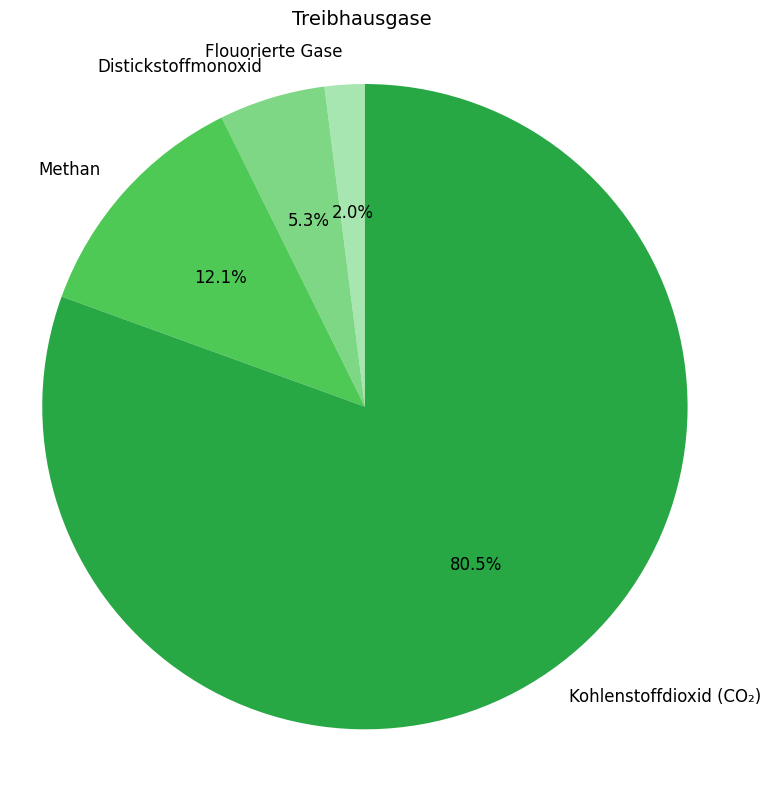

In [ ]:
import matplotlib.pyplot as plt

# Beispiel-Daten
labels = ['Flouorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.3]

# Grüntöne (abgestuft)
gruentoene = ['#a8e6b1', '#7dd784', '#4fc956', '#28a745']

# Kreisdiagramm
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=gruentoene,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'}
)

# Gleichmäßiger Kreis
ax.axis('equal')
plt.title('Treibhausgase ', fontsize=14)
plt.tight_layout()
plt.show()


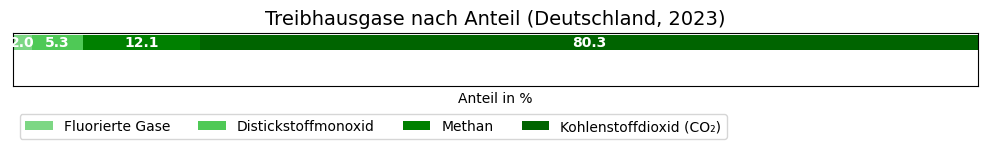

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = ['Fluorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.3]
farben = [ '#7dd784', '#4fc956', 'green', 'darkgreen']

# Gesamtsumme zur Prozentberechnung
gesamt = sum(werte)
prozent = [v / gesamt * 100 for v in werte]

# Plot vorbereiten
fig, ax = plt.subplots(figsize=(10, 2))
start = 0

# Segmentweise aufbauen
for i in range(len(werte)):
    ax.barh(0, werte[i], left=start, color=farben[i], height=0.5)
    ax.text(start + werte[i]/2, 0, f"{werte[i]:.1f}", va='center', ha='center', fontsize=10, color='white', weight='bold')
    start += werte[i]

# Achsen & Layout
ax.set_xlim(0, gesamt)
ax.set_yticks([])
ax.set_xlabel("Anteil in %")
ax.set_title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
ax.set_xticks([])

# Legende (außerhalb)
for i, label in enumerate(labels):
    ax.barh(-1, 0, color=farben[i], label=label)
ax.legend(ncol=4, bbox_to_anchor=(0, -0.4), loc='upper left')

plt.tight_layout()
plt.show()


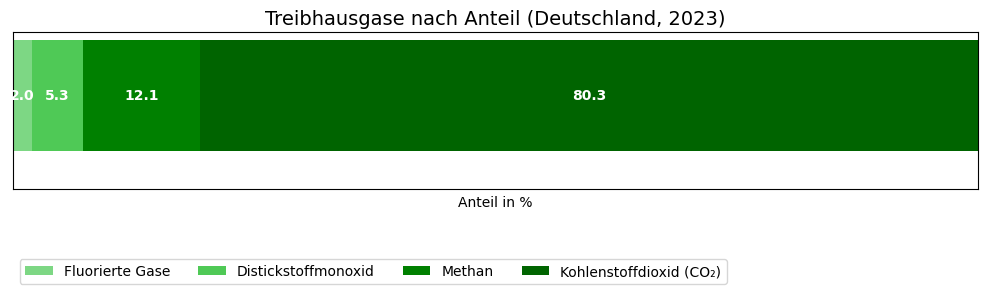

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = ['Fluorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.3]
farben = [ '#7dd784', '#4fc956', 'green', 'darkgreen']
# Gesamtsumme
gesamt = sum(werte)

# Plot
fig, ax = plt.subplots(figsize=(10, 3.5))  # Höhe leicht erhöht für dickeren Balken
start = 0
balkenhoehe = 1.8  # << Hier steuerst du die Dicke des Balkens

# Zeichne den gestapelten Balken
for i in range(len(werte)):
    ax.barh(0, werte[i], left=start, color=farben[i], height=balkenhoehe)
    ax.text(start + werte[i]/2, 0, f"{werte[i]:.1f}", va='center', ha='center', fontsize=10, color='white', weight='bold')
    start += werte[i]

# Achsen entfernen
ax.set_xlim(0, gesamt)
ax.set_yticks([])
ax.set_xticks([])
ax.set_xlabel("Anteil in %")
ax.set_title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)

# Legende unten
for i, label in enumerate(labels):
    ax.barh(-1, 0, color=farben[i], label=label)
ax.legend(ncol=4, bbox_to_anchor=(0, -0.4), loc='upper left')

plt.tight_layout()
plt.show()


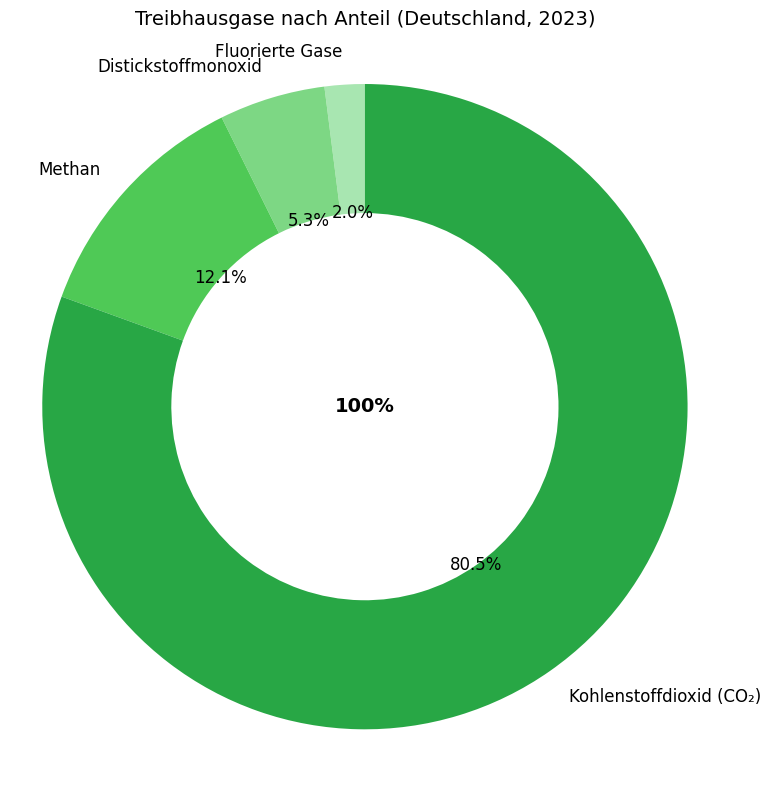

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = ['Fluorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.3]
farben = ['#a8e6b1', '#7dd784', '#4fc956', '#28a745']

# Kreis-/Donut-Diagramm mit Loch
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.4}  # << macht es zum Donut!
)

# Optionaler Titel in der Mitte (z. B. Gesamt oder Kontext)
plt.text(0, 0, '100%', ha='center', va='center', fontsize=14, fontweight='bold')

# Gleichmäßiger Kreis
ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


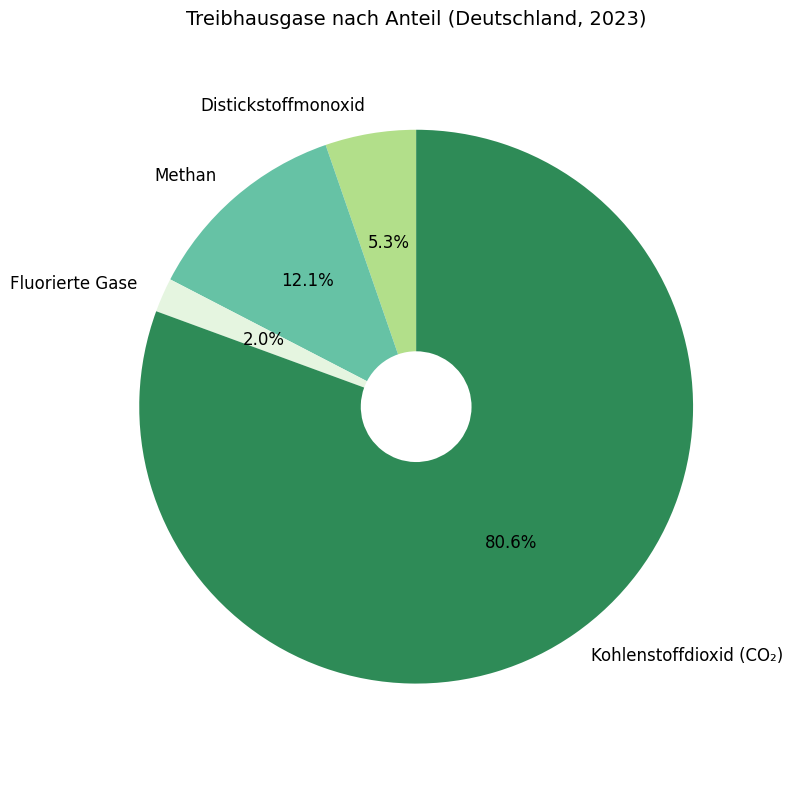

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = [ 'Distickstoffmonoxid', 'Methan','Fluorierte Gase', 'Kohlenstoffdioxid (CO₂)']
werte = [5.3, 12.1,2.0,  80.6]
farben = [ '#b2df8a', '#66c2a5','#e5f5e0', '#2e8b57']


# Donut-Plot mit schmalerem Loch
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.8}  # << kleineres Loch (vorher 0.4)
)

# Entferne Text in der Mitte – wir schreiben nichts hinein
# (Kein plt.text(...) nötig)

# Gleichmäßiger Kreis
ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


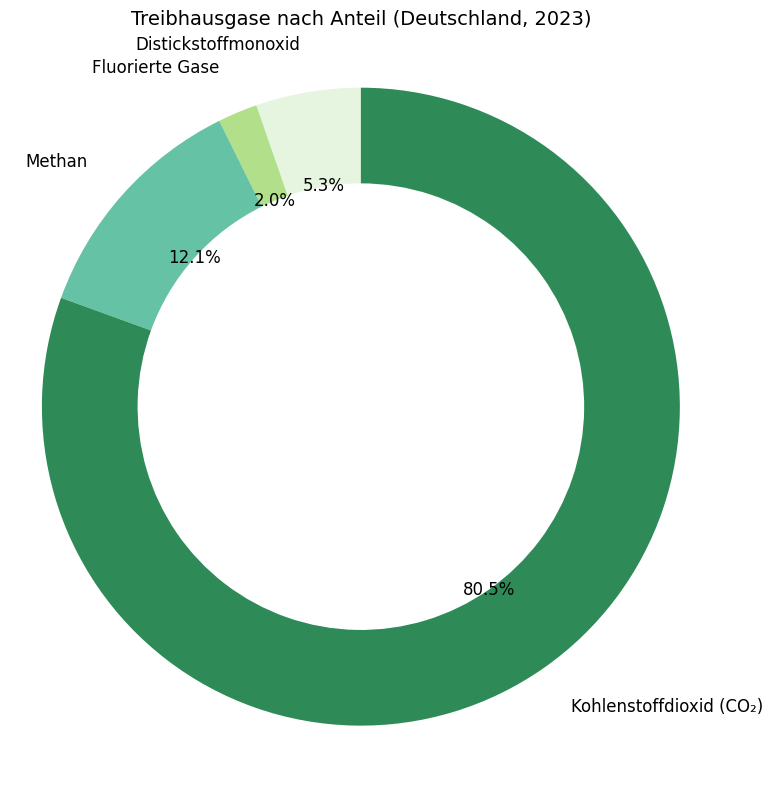

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = [ 'Distickstoffmonoxid','Fluorierte Gase', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [ 5.3,2.0, 12.1, 80.3]
farben = ['#e5f5e0', '#b2df8a', '#66c2a5', '#2e8b57']

# Donut-Diagramm mit optimierten Beschriftungen
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.3},
    labeldistance=1.15,   # Abstand der Beschriftung vom Kreis
    pctdistance=0.7       # Abstand der Prozentwerte zum Kreiszentrum
)

# Kreis gleichmäßig
ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


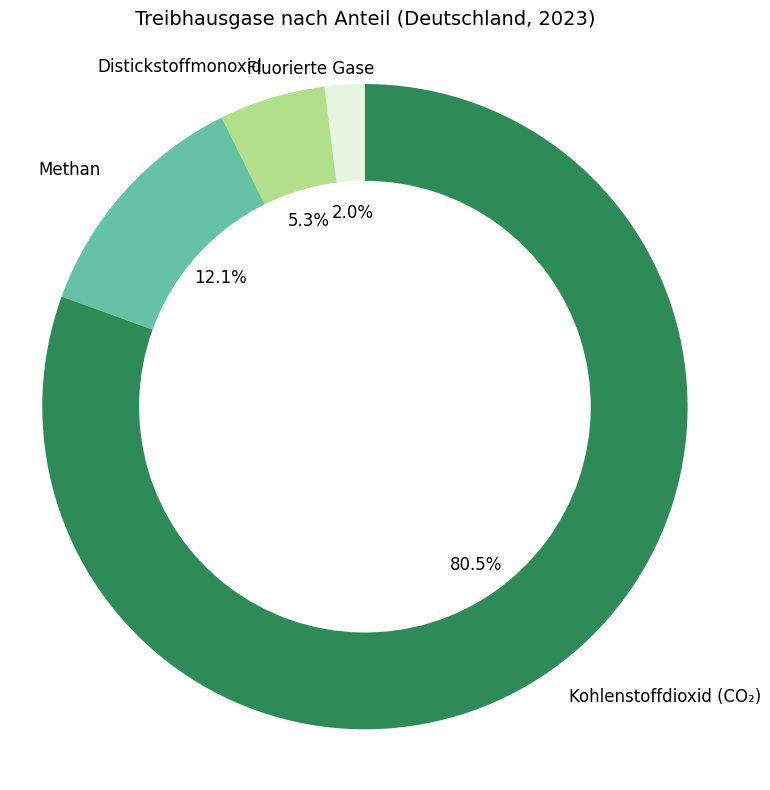

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = ['Fluorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.3]
farben = ['#e5f5e0', '#b2df8a', '#66c2a5', '#2e8b57']

# Donut-Diagramm
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.3}  # gleich wie zuvor
)

# Beschriftung von "Fluorierte Gase" (Index 0) etwas nach rechts und unten verschieben
x, y = texts[0].get_position()
texts[0].set_position((x + 0.1, y - 0.05))  # feine Anpassung nach rechts/unten

# Gleichmäßiger Kreis
ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


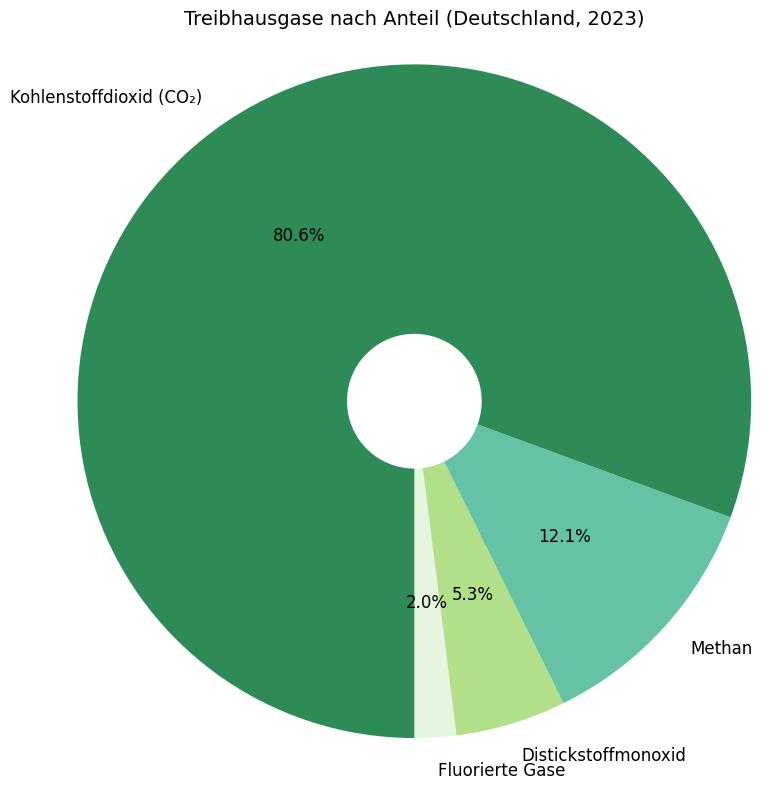

In [ ]:
import matplotlib.pyplot as plt

# Daten
labels = ['Fluorierte Gase', 'Distickstoffmonoxid', 'Methan', 'Kohlenstoffdioxid (CO₂)']
werte = [2.0, 5.3, 12.1, 80.6]
farben = ['#e5f5e0', '#b2df8a', '#66c2a5', '#2e8b57']

# Donut-Plot mit angepasstem Startwinkel
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    werte,
    labels=labels,
    colors=farben,
    autopct='%1.1f%%',
    startangle=270,  # << Dreht das große Segment nach oben
    textprops={'fontsize': 12, 'color': 'black'},
    wedgeprops={'width': 0.8}
)

# Kreisform
ax.axis('equal')
plt.title("Treibhausgase nach Anteil (Deutschland, 2023)", fontsize=14)
plt.tight_layout()
plt.show()


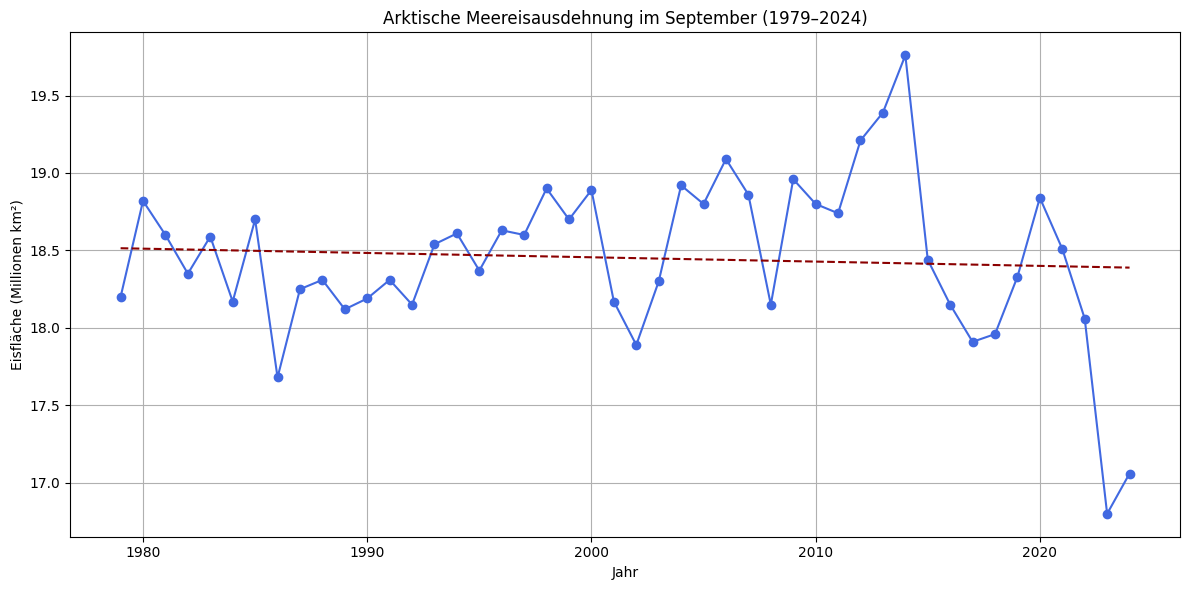

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Datei einlesen (z. B. September-Daten von NSIDC)
file_path = "S_09_extent_v3.0.csv"
df = pd.read_csv(file_path, header=None)

# Spalten benennen
df.columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]

# Nur relevante Spalten verwenden
df = df[["Year", "Extent"]].copy()
df["Year"] = pd.to_numeric(df["Year"], errors='coerce')
df["Extent"] = pd.to_numeric(df["Extent"], errors='coerce')

# Trendlinie berechnen (lineare Regression mit numpy)
import numpy as np

df = df.dropna(subset=["Year", "Extent"])

z = np.polyfit(df["Year"], df["Extent"], 1)
p = np.poly1d(z)

# Diagramm zeichnen
plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], marker='o', linestyle='-', color='royalblue', label="Meereisausdehnung im September")
plt.plot(df["Year"], p(df["Year"]), linestyle='--', color='darkred', label=f"Trendlinie ({z[0]:.2f} Mio. km²/Jahr)")
plt.title("Arktische Meereisausdehnung im September (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Millionen km²)")
plt.grid(True)
plt.tight_layout()
plt.show()


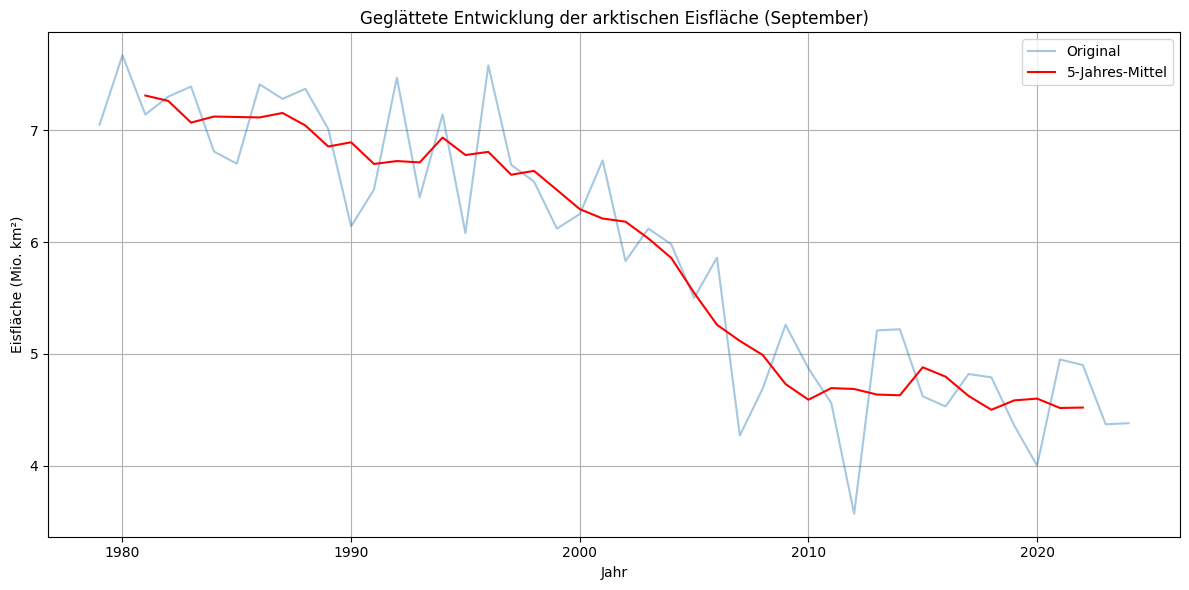

In [ ]:
df["RollingMean"] = df["Extent"].rolling(window=5, center=True).mean()

plt.figure(figsize=(12, 6))
plt.plot(df["Year"], df["Extent"], label="Original", alpha=0.4)
plt.plot(df["Year"], df["RollingMean"], label="5-Jahres-Mittel", color='red')
plt.title("Geglättete Entwicklung der arktischen Eisfläche (September)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Mio. km²)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


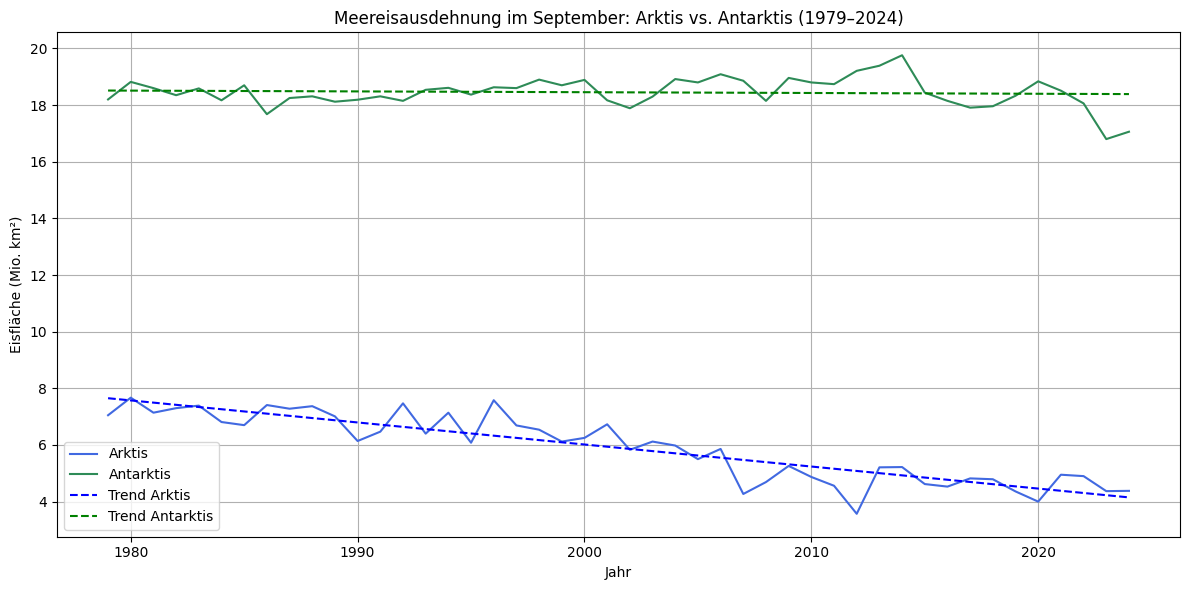

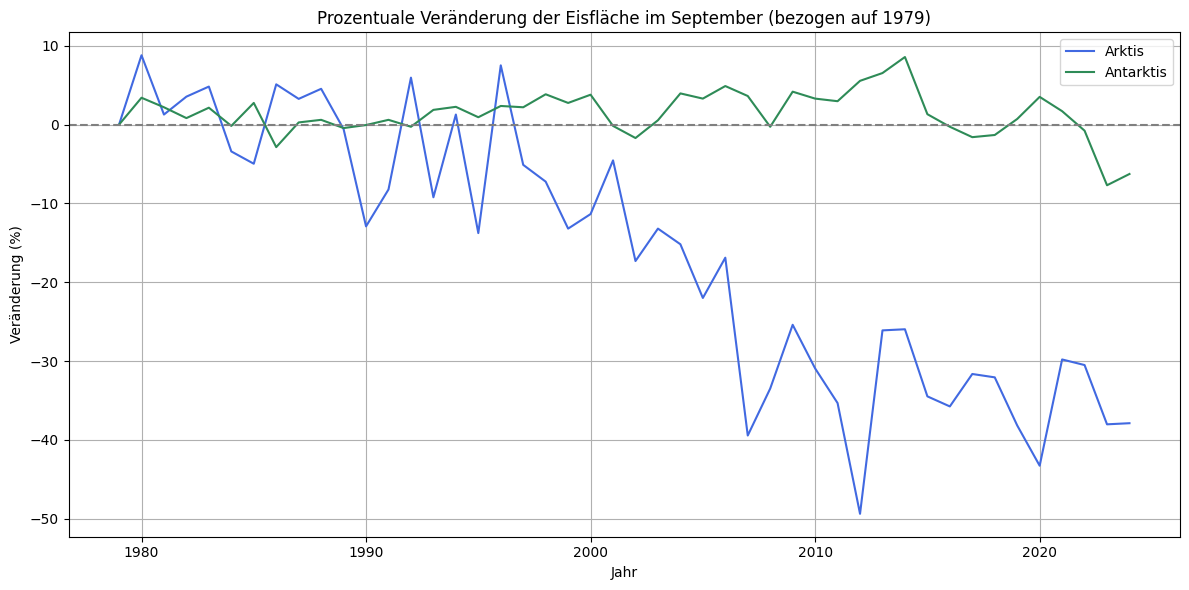

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Dateien einlesen
arktis_df = pd.read_csv("data/N_09_extent_v3.0.csv", header=None)
antarktis_df = pd.read_csv("data/S_09_extent_v3.0.csv", header=None)

# Spalten benennen
columns = ["Year", "Month", "Source", "Region", "Extent", "Area"]
arktis_df.columns = antarktis_df.columns = columns

# Nur Jahr & Extent
arktis = arktis_df[["Year", "Extent"]].dropna()
antarktis = antarktis_df[["Year", "Extent"]].dropna()

# Datentypen bereinigen
arktis["Year"] = pd.to_numeric(arktis["Year"], errors="coerce")
arktis["Extent"] = pd.to_numeric(arktis["Extent"], errors="coerce")
antarktis["Year"] = pd.to_numeric(antarktis["Year"], errors="coerce")
antarktis["Extent"] = pd.to_numeric(antarktis["Extent"], errors="coerce")

# Doppelte Jahre mitteln
arktis = arktis.groupby("Year").mean().reset_index()
antarktis = antarktis.groupby("Year").mean().reset_index()

# Prozentuale Veränderung zum ersten Jahr
arktis_base = arktis.iloc[0]["Extent"]
antarktis_base = antarktis.iloc[0]["Extent"]
arktis["Change_%"] = (arktis["Extent"] - arktis_base) / arktis_base * 100
antarktis["Change_%"] = (antarktis["Extent"] - antarktis_base) / antarktis_base * 100

# Trendlinien berechnen
arktis_trend = np.poly1d(np.polyfit(arktis["Year"], arktis["Extent"], 1))
antarktis_trend = np.poly1d(np.polyfit(antarktis["Year"], antarktis["Extent"], 1))

# 📈 Plot: Eisfläche im September
plt.figure(figsize=(12, 6))
plt.plot(arktis["Year"], arktis["Extent"], label="Arktis", color="royalblue")
plt.plot(antarktis["Year"], antarktis["Extent"], label="Antarktis", color="seagreen")
plt.plot(arktis["Year"], arktis_trend(arktis["Year"]), linestyle="--", color="blue", label="Trend Arktis")
plt.plot(antarktis["Year"], antarktis_trend(antarktis["Year"]), linestyle="--", color="green", label="Trend Antarktis")
plt.title("Meereisausdehnung im September: Arktis vs. Antarktis (1979–2024)")
plt.xlabel("Jahr")
plt.ylabel("Eisfläche (Mio. km²)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 📉 Plot: Prozentuale Veränderung
plt.figure(figsize=(12, 6))
plt.plot(arktis["Year"], arktis["Change_%"], label="Arktis", color="royalblue")
plt.plot(antarktis["Year"], antarktis["Change_%"], label="Antarktis", color="seagreen")
plt.axhline(0, color='gray', linestyle='--')
plt.title("Prozentuale Veränderung der Eisfläche im September (bezogen auf 1979)")
plt.xlabel("Jahr")
plt.ylabel("Veränderung (%)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

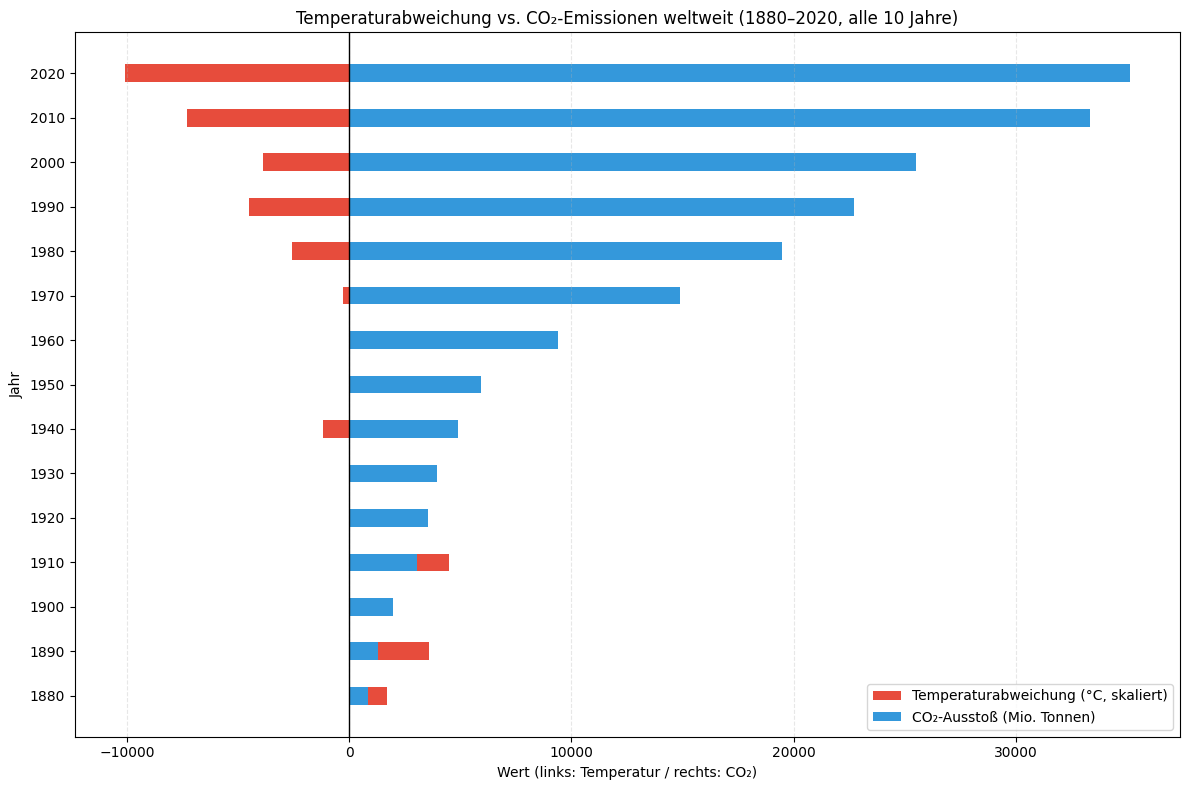

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# CO2-Daten
df_co2 = pd.read_csv("data/owid-co2-data.csv")
df_world = df_co2[(df_co2['country'] == 'World') & (df_co2['year'] >= 1880) & (df_co2['year'] <= 2020)]
df_world = df_world[df_world['year'] % 10 == 0][['year', 'co2']].dropna()

# Temperaturdaten
df_temp = pd.read_csv("data/nasa_temperature.csv", skiprows=1)
df_temp.rename(columns={df_temp.columns[0]: 'year'}, inplace=True)
df_temp = df_temp[['year', 'J-D']].dropna()
df_temp['J-D'] = pd.to_numeric(df_temp['J-D'], errors='coerce')
df_temp = df_temp[df_temp['year'] % 10 == 0]
df_temp = df_temp[(df_temp['year'] >= 1880) & (df_temp['year'] <= 2020)]

# Gemeinsame Jahre
jahre = sorted(set(df_world['year']) & set(df_temp['year']))
df_co2 = df_world[df_world['year'].isin(jahre)].set_index('year')
df_temp = df_temp[df_temp['year'].isin(jahre)].set_index('year')

# Werte vorbereiten
co2 = df_co2['co2'].values
temp = df_temp['J-D'].values
jahre = np.array(jahre)

# Temperatur skalieren & links darstellen (alle ins Negative drehen)
scale = 10000
temp_links = -temp * scale

# Plot
fig, ax = plt.subplots(figsize=(12, 8))
bar_width = 4

ax.barh(jahre, temp_links, color='#e74c3c', height=bar_width, label='Temperaturabweichung (°C, skaliert)', align='center')
ax.barh(jahre, co2,        color='#3498db', height=bar_width, label='CO₂-Ausstoß (Mio. Tonnen)', align='center')

# Styling
ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(jahre)
ax.set_xlabel('Wert (links: Temperatur / rechts: CO₂)')
ax.set_ylabel('Jahr')
ax.set_title('Temperaturabweichung vs. CO₂-Emissionen weltweit (1880–2020, alle 10 Jahre)')
ax.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


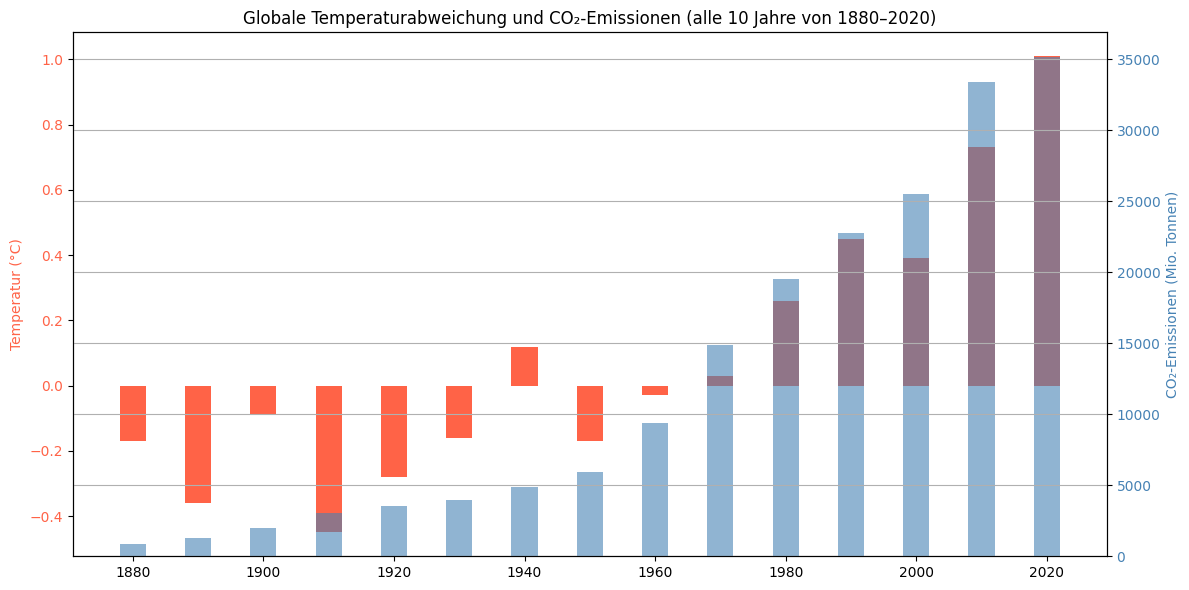

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# CO2-Daten einlesen
df_co2 = pd.read_csv("data/owid-co2-data.csv")
df_world = df_co2[(df_co2['country'] == 'World') & 
                  (df_co2['year'] >= 1880) & 
                  (df_co2['year'] <= 2020) & 
                  (df_co2['year'] % 10 == 0)][['year', 'co2']].dropna()

# Temperaturdaten einlesen
df_temp = pd.read_csv("data/nasa_temperature.csv", skiprows=1)
df_temp.rename(columns={df_temp.columns[0]: 'year'}, inplace=True)
df_temp = df_temp[['year', 'J-D']].dropna()
df_temp['J-D'] = pd.to_numeric(df_temp['J-D'], errors='coerce')
df_temp = df_temp[(df_temp['year'] >= 1880) & (df_temp['year'] <= 2020) & (df_temp['year'] % 10 == 0)]

# Gemeinsame Jahre
jahre = sorted(set(df_world['year']) & set(df_temp['year']))
df_co2 = df_world[df_world['year'].isin(jahre)].set_index('year')
df_temp = df_temp[df_temp['year'].isin(jahre)].set_index('year')

co2 = df_co2['co2'].values
temp = df_temp['J-D'].values
jahre = list(df_co2.index)

# Plot mit zwei Y-Achsen
fig, ax1 = plt.subplots(figsize=(12, 6))

# Temperatur links
ax1.bar(jahre, temp, color='tomato', width=4, label='Temperaturabweichung (°C)')
ax1.set_ylabel('Temperatur (°C)', color='tomato')
ax1.tick_params(axis='y', labelcolor='tomato')

# CO2 rechts
ax2 = ax1.twinx()
ax2.bar(jahre, co2, color='steelblue', width=4, alpha=0.6, label='CO₂-Ausstoß (Mio. Tonnen)')
ax2.set_ylabel('CO₂-Emissionen (Mio. Tonnen)', color='steelblue')
ax2.tick_params(axis='y', labelcolor='steelblue')

plt.title("Globale Temperaturabweichung und CO₂-Emissionen (alle 10 Jahre von 1880–2020)")
plt.xlabel("Jahr")
plt.grid(True)
plt.tight_layout()
plt.show()


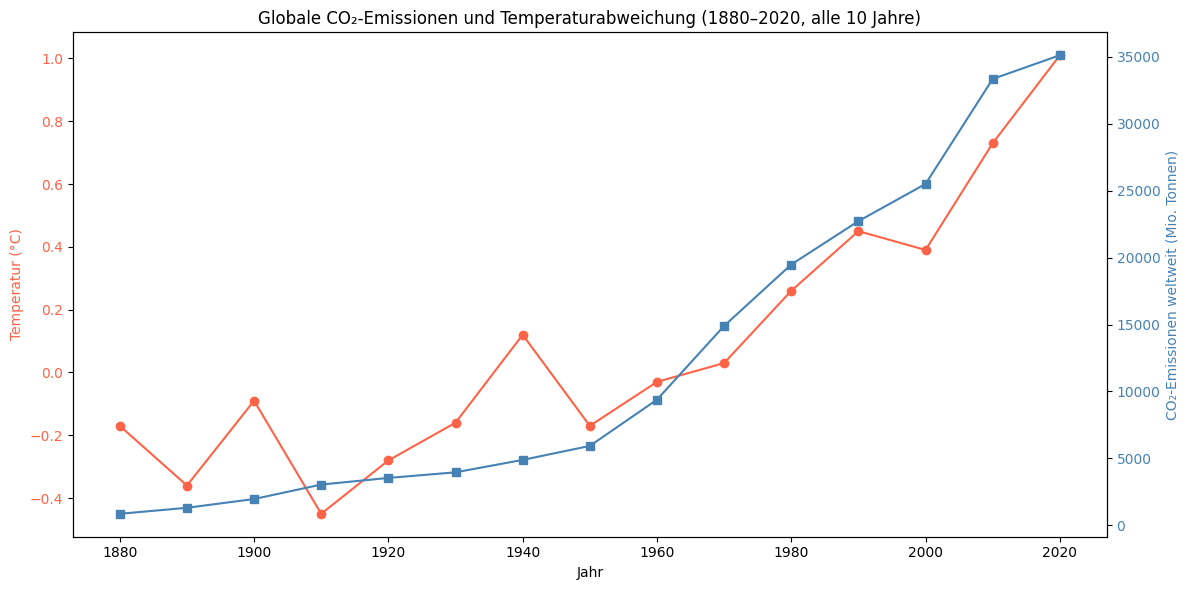

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Daten einlesen
df_co2 = pd.read_csv("data/owid-co2-data.csv")
df_temp = pd.read_csv("data/nasa_temperature.csv", skiprows=1)

# CO2 filtern: nur "World", alle 10 Jahre ab 1880
df_world = df_co2[(df_co2['country'] == 'World') & (df_co2['year'] >= 1880)]
df_world = df_world[df_world['year'] % 10 == 0][['year', 'co2']].dropna()

# Temperaturdaten vorbereiten
df_temp.rename(columns={df_temp.columns[0]: 'year'}, inplace=True)
df_temp = df_temp[['year', 'J-D']].dropna()
df_temp['J-D'] = pd.to_numeric(df_temp['J-D'], errors='coerce')
df_temp = df_temp[(df_temp['year'] % 10 == 0) & (df_temp['year'] >= 1880) & (df_temp['year'] <= 2020)]

# Gemeinsame Jahre matchen
jahre = sorted(set(df_world['year']) & set(df_temp['year']))
df_co2 = df_world[df_world['year'].isin(jahre)].set_index('year')
df_temp = df_temp[df_temp['year'].isin(jahre)].set_index('year')

# Plot erstellen
fig, ax1 = plt.subplots(figsize=(12, 6))

# Temperaturlinie (linke Achse)
ax1.plot(df_temp.index, df_temp['J-D'], color='tomato', marker='o', label='Temperaturabweichung (°C)')
ax1.set_ylabel("Temperatur (°C)", color='tomato')
ax1.tick_params(axis='y', labelcolor='tomato')

# CO2-Linie (rechte Achse)
ax2 = ax1.twinx()
ax2.plot(df_co2.index, df_co2['co2'], color='steelblue', marker='s', label='CO₂-Emissionen (Mio. Tonnen)')
ax2.set_ylabel("CO₂-Emissionen weltweit (Mio. Tonnen)", color='steelblue')
ax2.tick_params(axis='y', labelcolor='steelblue')

# Titel und Achsen
ax1.set_title("Globale CO₂-Emissionen und Temperaturabweichung (1880–2020, alle 10 Jahre)")
ax1.set_xlabel("Jahr")
fig.tight_layout()
plt.show()


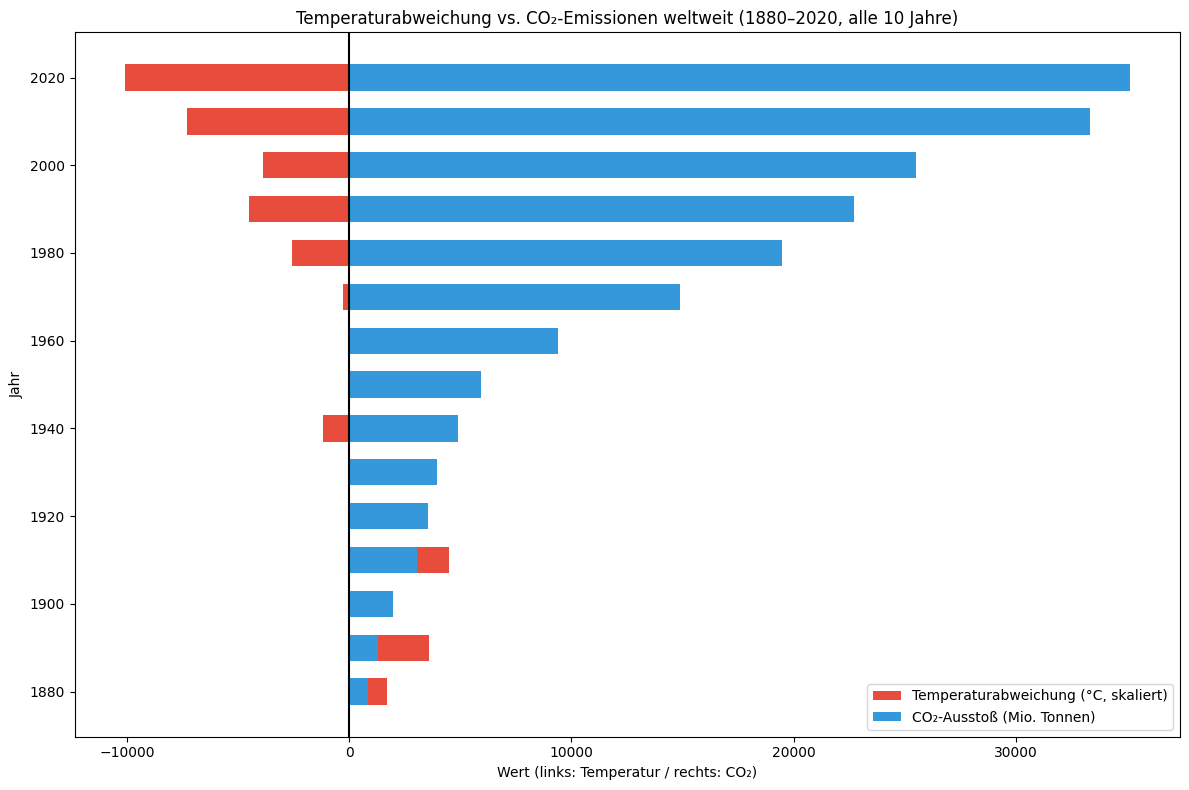

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================
# CO₂-Daten vorbereiten
# =====================
df_co2 = pd.read_csv("data/owid-co2-data.csv")
df_world = df_co2[
    (df_co2['country'] == 'World') &
    (df_co2['year'] >= 1880) &
    (df_co2['year'] <= 2020) &
    (df_co2['year'] % 10 == 0)
][['year', 'co2']].dropna()

# ============================
# Temperaturdaten vorbereiten
# ============================
df_temp = pd.read_csv("data/nasa_temperature.csv", skiprows=1)
df_temp.rename(columns={df_temp.columns[0]: 'year'}, inplace=True)
df_temp = df_temp[['year', 'J-D']].dropna()
df_temp['J-D'] = pd.to_numeric(df_temp['J-D'], errors='coerce')
df_temp = df_temp[
    (df_temp['year'] >= 1880) &
    (df_temp['year'] <= 2020) &
    (df_temp['year'] % 10 == 0)
]

# ====================
# Gemeinsame Jahre und Werte
# ====================
jahre = sorted(set(df_world['year']) & set(df_temp['year']))
df_co2 = df_world[df_world['year'].isin(jahre)].set_index('year')
df_temp = df_temp[df_temp['year'].isin(jahre)].set_index('year')

co2 = df_co2['co2'].values
temp = df_temp['J-D'].values
jahre = np.array(jahre)

# ====================================
# Temperatur skalieren und invertieren
# ====================================
scale = 10000  # damit Größenverhältnisse vergleichbar sind
temp_links = -temp * scale  # ins Negative für linke Seite

# ============
# Visualisierung
# ============
fig, ax = plt.subplots(figsize=(12, 8))

bar_width = 6

# Temperatur links (rot, negativ dargestellt)
ax.barh(jahre, temp_links, color='#e74c3c', height=bar_width, label='Temperaturabweichung (°C, skaliert)')

# CO₂ rechts (blau)
ax.barh(jahre, co2, color='#3498db', height=bar_width, label='CO₂-Ausstoß (Mio. Tonnen)')

# Mittellinie
ax.axvline(0, color='black')

# Achsen & Titel
ax.set_xlabel("Wert (links: Temperatur / rechts: CO₂)")
ax.set_ylabel("Jahr")
ax.set_title("Temperaturabweichung vs. CO₂-Emissionen weltweit (1880–2020, alle 10 Jahre)")
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


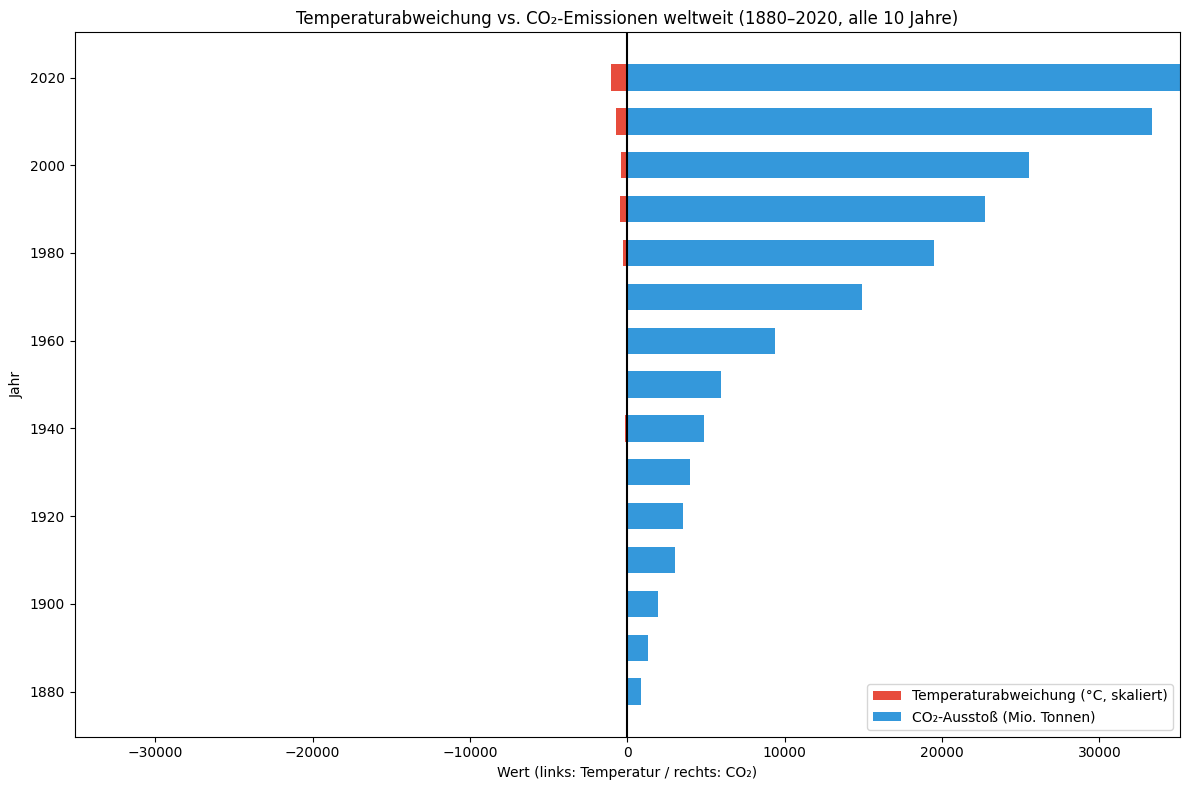

In [17]:
# Temperatur skalieren – kleinerer Faktor
scale = 1000
temp_links = -temp * scale  # immer noch negativ für linke Richtung

# Visualisierung
fig, ax = plt.subplots(figsize=(12, 8))
bar_width = 6

# Temperatur (links)
ax.barh(jahre, temp_links, color='#e74c3c', height=bar_width, label='Temperaturabweichung (°C, skaliert)')

# CO₂ (rechts)
ax.barh(jahre, co2, color='#3498db', height=bar_width, label='CO₂-Ausstoß (Mio. Tonnen)')

# Mittellinie
ax.axvline(0, color='black')

# Achsen und Titel
ax.set_xlabel("Wert (links: Temperatur / rechts: CO₂)")
ax.set_ylabel("Jahr")
ax.set_title("Temperaturabweichung vs. CO₂-Emissionen weltweit (1880–2020, alle 10 Jahre)")
ax.legend(loc='lower right')

# Optional: Symmetrische Achsenbegrenzung setzen
max_val = max(co2.max(), abs(temp_links).max())
ax.set_xlim(-max_val, max_val)

plt.tight_layout()
plt.show()
